# Rn-222 Per-Run Fit — Ratio-Constrained Model

**Prerequisite:** In the old notebook, save `rn_events` first:
```python
rn_events.to_pickle('/project2/lgrandi/jietang/sr3_commissioning/sr3_s1only_corrected_for_fit_pp.pkl')
```

**Key improvements:**
1. **Ratio-constrained model**: 1 scale parameter instead of 5 independent mu → 12 vs 16 params
2. **Per-run auto-calibration**: `find_peaks` locates Rn-222, then scales other peaks by energy ratios
3. **Tiered fallback**: ratio(indep sigma) → ratio(shared sigma) → standard 5-mu → give up

---
## 1. Imports & Setup

In [1]:
import sys
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import cutax
import strax
import straxen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from datetime import datetime, timezone
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 15)
pd.set_option('display.expand_frame_repr', False)

def safe_tight(fig=None):
    try:
        (fig or plt).tight_layout()
    except Exception:
        pass

print('Setup complete.')

Setup complete.


/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/xgboost/core.py:265: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc 2.28+) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s1_width.S1Width'>
  warnings.warn(f"Removing cut {cut}", UserWarning)
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s2_width.S2Width'>
  warnings.warn(f"Removing cu

---
## 2. Load `rn_events` (pre-corrected) + Run List

In [2]:
# ── Load pre-corrected rn_events (saved from old notebook) ──
rn_events = pd.read_pickle(
    '/project2/lgrandi/jietang/sr3_commissioning/sr3_s1only_corrected_for_fit_pp.pkl'
)
print(f'rn_events: {len(rn_events):,} events')
print(f'Columns: {list(rn_events.columns)}')
print(f'Time range: {datetime.fromtimestamp(rn_events["time"].min()/1e9, tz=timezone.utc).strftime("%Y-%m-%d")} -> '
      f'{datetime.fromtimestamp(rn_events["time"].max()/1e9, tz=timezone.utc).strftime("%Y-%m-%d")} UTC')
print(f'area_2_corrected range: {rn_events["area_2_corrected"].min():.0f} – {rn_events["area_2_corrected"].max():.0f} PE')

rn_events: 517,844 events
Columns: ['time', 'endtime_x', 'area', 'area_fraction_top', 'range_50p_area', 'type', 'x_naive', 'y_naive', 'endtime_y', 'x', 'y', 'r', 'r2', 'run_name', 'area_aft_corrected', 'r2_aft_corrected', 'corr2_factor', 'area_2_corrected', 'corr3_factor']
Time range: 2026-05-03 -> 2026-07-02 UTC
area_2_corrected range: 2020 – 166560 PE


In [3]:
# ── Run list from straxen ──
st = straxen.contexts.xenonnt_online(
    output_folder='/scratch/midway3/jietang/strax_data'
)
st.storage.append(
    strax.DataDirectory('/project/lgrandi-shared/commissioning/', readonly=True)
)

runs_sr3 = st.select_runs(
    run_mode='tpc_bkg',
    exclude_tags=['abandon', 'messy', 'timing_issue'],
    include_tags=['s1_only'],
    available=('peak_basics'),
)

MIN_RUN_DATE = '2026-05-01'
min_run_s = pd.Timestamp(MIN_RUN_DATE, tz='UTC').timestamp()
runs_sr3['start_s'] = runs_sr3['start'].apply(lambda x: x.timestamp())
runs_sr3 = runs_sr3[runs_sr3['start_s'] >= min_run_s].copy()

print(f'Runs since {MIN_RUN_DATE}: {len(runs_sr3)}')
print(f'Run range: {runs_sr3["name"].min()} – {runs_sr3["name"].max()}')

Provides of multi-output plugins overlap, deregister old plugins <class 'straxen.plugins.merged_s2s.merged_s2s.MergedS2s'>.


You specified _auto_append_rucio_local=True and you are not on dali compute nodes, so we will add the following rucio local path: /project/lgrandi/rucio/


Checking data availability:   0%|          | 0/2 [00:00<?, ?it/s]

Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin


Runs since 2026-05-01: 494
Run range: 079694 – 083645


---
## 3. Peak Model Definitions

In [4]:
# ═══════════════════════════════════════════════════════════════
# PEAK DEFINITIONS — Q-values (alpha + recoil)
# ═══════════════════════════════════════════════════════════════

PEAK_NAMES   = ['Rn-222', 'Po-218', 'Po-214']
PEAK_ENERGIES = np.array([5.59, 6.115, 7.834])  # MeV (Q-value)
E_RN222 = 5.59
N_PEAKS = len(PEAK_NAMES)

for name, e in zip(PEAK_NAMES, PEAK_ENERGIES):
    print('  %-10s  Q=%.2f MeV  Q/Q_Rn222=%.4f' % (name, e, e/E_RN222))


  Rn-222      5.49 MeV  E/E_Rn222 = 1.0000
  Po-218      6.00 MeV  E/E_Rn222 = 1.0929
  Rn-220      6.29 MeV  E/E_Rn222 = 1.1457
  Po-216      6.78 MeV  E/E_Rn222 = 1.2350
  Po-214      7.69 MeV  E/E_Rn222 = 1.4007


In [5]:
# ═══════════════════════════════════════════════════════════════
# GAUSSIAN MODELS (3 variants)
# ═══════════════════════════════════════════════════════════════

# Standard: 5 independent mu + 5 independent sigma + bg  (16 params)
def multi_gaussian(x, *params):
    bg = params[-1]
    result = bg * np.ones_like(x)
    for i in range(N_PEAKS):
        amp, mu, sig = params[3*i], params[3*i + 1], params[3*i + 2]
        result += amp * np.exp(-0.5 * ((x - mu) / sig)**2)
    return result

# Ratio-constrained: 1 scale + 5 indep sigma + bg  (12 params)
# mu_i = scale * (E_i / E_Rn222)
def multi_gaussian_ratio(x, *params):
    bg = params[-1]
    scale = params[N_PEAKS]
    result = bg * np.ones_like(x)
    for i in range(N_PEAKS):
        amp, sig = params[i], params[N_PEAKS + 1 + i]
        mu = scale * PEAK_ENERGIES[i] / E_RN222
        result += amp * np.exp(-0.5 * ((x - mu) / sig)**2)
    return result

# Ratio-constrained + shared sigma  (8 params) — most stable
def multi_gaussian_ratio_s(x, *params):
    bg = params[-1]
    scale = params[N_PEAKS]
    sig   = params[N_PEAKS + 1]
    result = bg * np.ones_like(x)
    for i in range(N_PEAKS):
        amp = params[i]
        mu  = scale * PEAK_ENERGIES[i] / E_RN222
        result += amp * np.exp(-0.5 * ((x - mu) / sig)**2)
    return result

print(f'multi_gaussian          — 5 mu + 5 sigma + bg  ({N_PEAKS*3+1} params)')
print(f'multi_gaussian_ratio    — 1 scale + 5 sigma + bg  ({N_PEAKS*2+2} params)')
print(f'multi_gaussian_ratio_s  — 1 scale + 1 sigma + bg  ({N_PEAKS+3} params)')

multi_gaussian          — 5 mu + 5 sigma + bg  (16 params)
multi_gaussian_ratio    — 1 scale + 5 sigma + bg  (12 params)
multi_gaussian_ratio_s  — 1 scale + 1 sigma + bg  (8 params)


---
## 4. Auto-Calibration + Two-Stage Fit

In [6]:
# ═══════════════════════════════════════════════════════════════
# Auto-calibrate guess from data (per-run peak finding)
# ═══════════════════════════════════════════════════════════════

def find_peak_guess(events, n_bins=150):
    if len(events) < 30:
        return None, None
    counts, edges = np.histogram(
        events['area_2_corrected'], bins=n_bins, range=[45e3, 80e3])
    centers = 0.5 * (edges[:-1] + edges[1:])
    peaks_idx, peaks_props = find_peaks(
        counts, height=counts.max()*0.05, distance=10)
    if len(peaks_idx) == 0:
        return None, None
    valid = (centers[peaks_idx] >= 45000) & (centers[peaks_idx] <= 60000)
    if not valid.any():
        return None, None
    rn222_idx = peaks_idx[valid][np.argmax(peaks_props['peak_heights'][valid])]
    rn222_mu  = centers[rn222_idx]
    return rn222_mu, rn222_mu * PEAK_ENERGIES / E_RN222

print('find_peak_guess() defined.')


find_peak_guess() defined.


In [7]:
# ═══════════════════════════════════════════════════════════════
# TWO-STAGE PER-RUN FIT
#   1. find_peaks → auto-calibrate Rn-222 position
#   2. Try: ratio(indep sigma) → ratio(shared sigma) → standard
# ═══════════════════════════════════════════════════════════════

def fit_one_run_v2(events, label='', rn222_ref=52000):
    n_ev = len(events)
    if n_ev < 50:
        return {'success': False, 'status': f'too_few_events({n_ev})',
                'method': None, 'p_fit': None, 'guess_mu': None,
                'fit_mu': None, 'n_events': n_ev, 'n_bins': 0, 'scale_pe': None}

    n_bins = min(300, max(80, n_ev // 4))
    counts, edges = np.histogram(
        events['area_2_corrected'], bins=n_bins, range=[45e3, 80e3])
    centers = 0.5 * (edges[:-1] + edges[1:])
    m = (centers >= 48000) & (centers <= 77000)
    x_fit, y_fit = centers[m], counts[m]
    y_err   = np.sqrt(np.maximum(y_fit, 1))

    # Stage 1: auto-calibrate
    rn222_pe, guess_mu = find_peak_guess(events, n_bins)
    if rn222_pe is None:
        guess_mu    = rn222_ref * PEAK_ENERGIES / E_RN222
        scale_guess = rn222_ref
    else:
        scale_guess = rn222_pe

    # Stage 2: try models in order
    for method_name, p0, lo, hi in _build_p0_all(x_fit, y_fit, guess_mu, scale_guess):
        model_fn = {'ratio': multi_gaussian_ratio,
                    'ratio_shared': multi_gaussian_ratio_s,
                    'standard': multi_gaussian}[method_name]
        try:
            p_fit, p_cov = curve_fit(model_fn, x_fit, y_fit, p0=p0, sigma=y_err,
                                     bounds=(lo, hi), maxfev=30000)
            # Extract mu
            if method_name in ('ratio', 'ratio_shared'):
                fit_mu = p_fit[N_PEAKS] * PEAK_ENERGIES / E_RN222
            else:
                fit_mu = np.array([p_fit[3*i+1] for i in range(N_PEAKS)])
            # Sanity: mu in range, Rn-222 not too far from guess
            if np.all((fit_mu > 40000) & (fit_mu < 85000)) \
               and abs(fit_mu[0] - guess_mu[0]) < 5000:
                return {'success': True, 'status': f'success_{method_name}',
                        'method': method_name, 'p_fit': p_fit,
                        'guess_mu': guess_mu, 'fit_mu': fit_mu,
                        'n_events': n_ev, 'n_bins': n_bins,
                        'scale_pe': scale_guess}
        except Exception:
            continue

    return {'success': False, 'status': 'all_models_failed',
            'method': None, 'p_fit': None, 'guess_mu': guess_mu,
            'fit_mu': None, 'n_events': n_ev, 'n_bins': n_bins,
            'scale_pe': scale_guess}


def _build_p0_all(x, y, guess_mu, scale_guess):
    """Yield (method_name, p0, lo, hi) for each model to try."""
    # ── ratio (indep sigma) ──
    p0, lo, hi = [], [], []
    for mu0 in guess_mu:
        idx = np.argmin(np.abs(x - mu0))
        p0.append(max(y[idx]*0.4, 3)); lo.append(0); hi.append(np.inf)
    p0.append(scale_guess); lo.append(scale_guess * 0.95); hi.append(scale_guess * 1.05)
    for _ in range(N_PEAKS):
        p0.append(800); lo.append(50); hi.append(8000)
    p0.append(1.0); lo.append(0); hi.append(np.inf)
    yield 'ratio', p0, lo, hi

    # ── ratio_shared ──
    p0, lo, hi = [], [], []
    for mu0 in guess_mu:
        idx = np.argmin(np.abs(x - mu0))
        p0.append(max(y[idx]*0.4, 3)); lo.append(0); hi.append(np.inf)
    p0.append(scale_guess); lo.append(scale_guess * 0.95); hi.append(scale_guess * 1.05)
    p0.append(800); lo.append(50); hi.append(8000)
    p0.append(1.0); lo.append(0); hi.append(np.inf)
    yield 'ratio_shared', p0, lo, hi

    # ── standard (5 independent mu) — wide bounds ──
    p0, lo, hi = [], [], []
    for mu0 in guess_mu:
        idx = np.argmin(np.abs(x - mu0))
        p0.extend([max(y[idx]*0.4, 3), mu0, 800])
        lo.extend([0, mu0 - 1500, 100])
        hi.extend([np.inf, mu0 + 1500, 3500])
    p0.append(1.0); lo.append(0); hi.append(np.inf)
    yield 'standard', p0, lo, hi

print('fit_one_run_v2() defined.')

fit_one_run_v2() defined.


---
## 5. Batch Fit All Runs

In [8]:
# ═══════════════════════════════════════════════════════════════
# BATCH FIT
# ═══════════════════════════════════════════════════════════════

def fit_all_runs_v2(runs_df, events_df, rn222_ref=52000):
    rows  = []
    stats = {}
    for idx, (_, run) in enumerate(runs_df.iterrows()):
        name = run['name']
        t0 = int(run['start_s'] * 1e9)
        t1 = int(float(run['end'].timestamp()) * 1e9)
        evts = events_df[(events_df['time'] >= t0) & (events_df['time'] < t1)]
        res  = fit_one_run_v2(evts, label=name, rn222_ref=rn222_ref)

        row = {'run': name, 'n_events': res['n_events'],
               'success': res['success'], 'status': res['status'],
               'method': res['method'], 'scale_guess_pe': res['scale_pe']}
        if res['p_fit'] is not None and res['fit_mu'] is not None:
            for i, iso in enumerate(PEAK_NAMES):
                row[f'fit_mu_{iso}']    = res['fit_mu'][i]
                if res['method'] in ('ratio', 'ratio_shared'):
                    if res['method'] == 'ratio':
                        row[f'fit_sigma_{iso}'] = res['p_fit'][N_PEAKS + 1 + i]
                    else:
                        row[f'fit_sigma_{iso}'] = res['p_fit'][N_PEAKS + 1]
                else:
                    row[f'fit_sigma_{iso}'] = res['p_fit'][3*i + 2]
        else:
            for i, iso in enumerate(PEAK_NAMES):
                row[f'fit_mu_{iso}'] = np.nan
                row[f'fit_sigma_{iso}'] = np.nan
        rows.append(row)
        stats[res['status']] = stats.get(res['status'], 0) + 1
        if (idx + 1) % 20 == 0 or idx == 0:
            print(f'  [{idx+1}/{len(runs_df)}] {name}  '
                  f'{res["n_events"]:4d} evts  {res["status"]}  [{res["method"]}]')

    df = pd.DataFrame(rows)
    n_ok = df['success'].sum()
    print(f"\n{'='*60}")
    print(f"  FIT SUMMARY: {n_ok}/{len(df)} runs ({100*n_ok/len(df):.1f}%)")
    print(f"{'='*60}")
    for st in sorted(stats):
        print(f"  {st:30s}  {stats[st]:4d}")
    ok_df = df[df['success']]
    print(f"\n  Method breakdown:")
    for m in ['ratio', 'ratio_shared', 'standard']:
        n = (ok_df['method'] == m).sum()
        if n > 0:
            print(f"    {m:25s}  {n:4d}")
    print(f"{'='*60}")
    return df

print('fit_all_runs_v2() defined.')

fit_all_runs_v2() defined.


In [9]:
# ── RUN ──
RN222_REF = 52000
df_fits = fit_all_runs_v2(runs_sr3, rn_events, rn222_ref=RN222_REF)

  [1/494] 083645     0 evts  too_few_events(0)  [None]
  [20/494] 083626     0 evts  too_few_events(0)  [None]
  [40/494] 083595     0 evts  too_few_events(0)  [None]
  [60/494] 083562     0 evts  too_few_events(0)  [None]
  [80/494] 083527     0 evts  too_few_events(0)  [None]
  [100/494] 083496     0 evts  too_few_events(0)  [None]
  [120/494] 083466  3394 evts  success_ratio  [ratio]
  [140/494] 083435  3322 evts  success_ratio  [ratio]
  [160/494] 083398  3410 evts  success_ratio  [ratio]
  [180/494] 083366  3457 evts  success_ratio  [ratio]
  [200/494] 081480   248 evts  success_ratio  [ratio]
  [220/494] 081311  1284 evts  success_ratio  [ratio]
  [240/494] 081272  1367 evts  success_ratio  [ratio]
  [260/494] 081230  1286 evts  success_ratio  [ratio]
  [280/494] 081170  1388 evts  success_ratio  [ratio]
  [300/494] 080783  1541 evts  success_ratio  [ratio]
  [320/494] 080716   217 evts  success_ratio  [ratio]
  [340/494] 080675    45 evts  too_few_events(45)  [None]
  [360/494] 

---
## 6. Diagnostic Plots

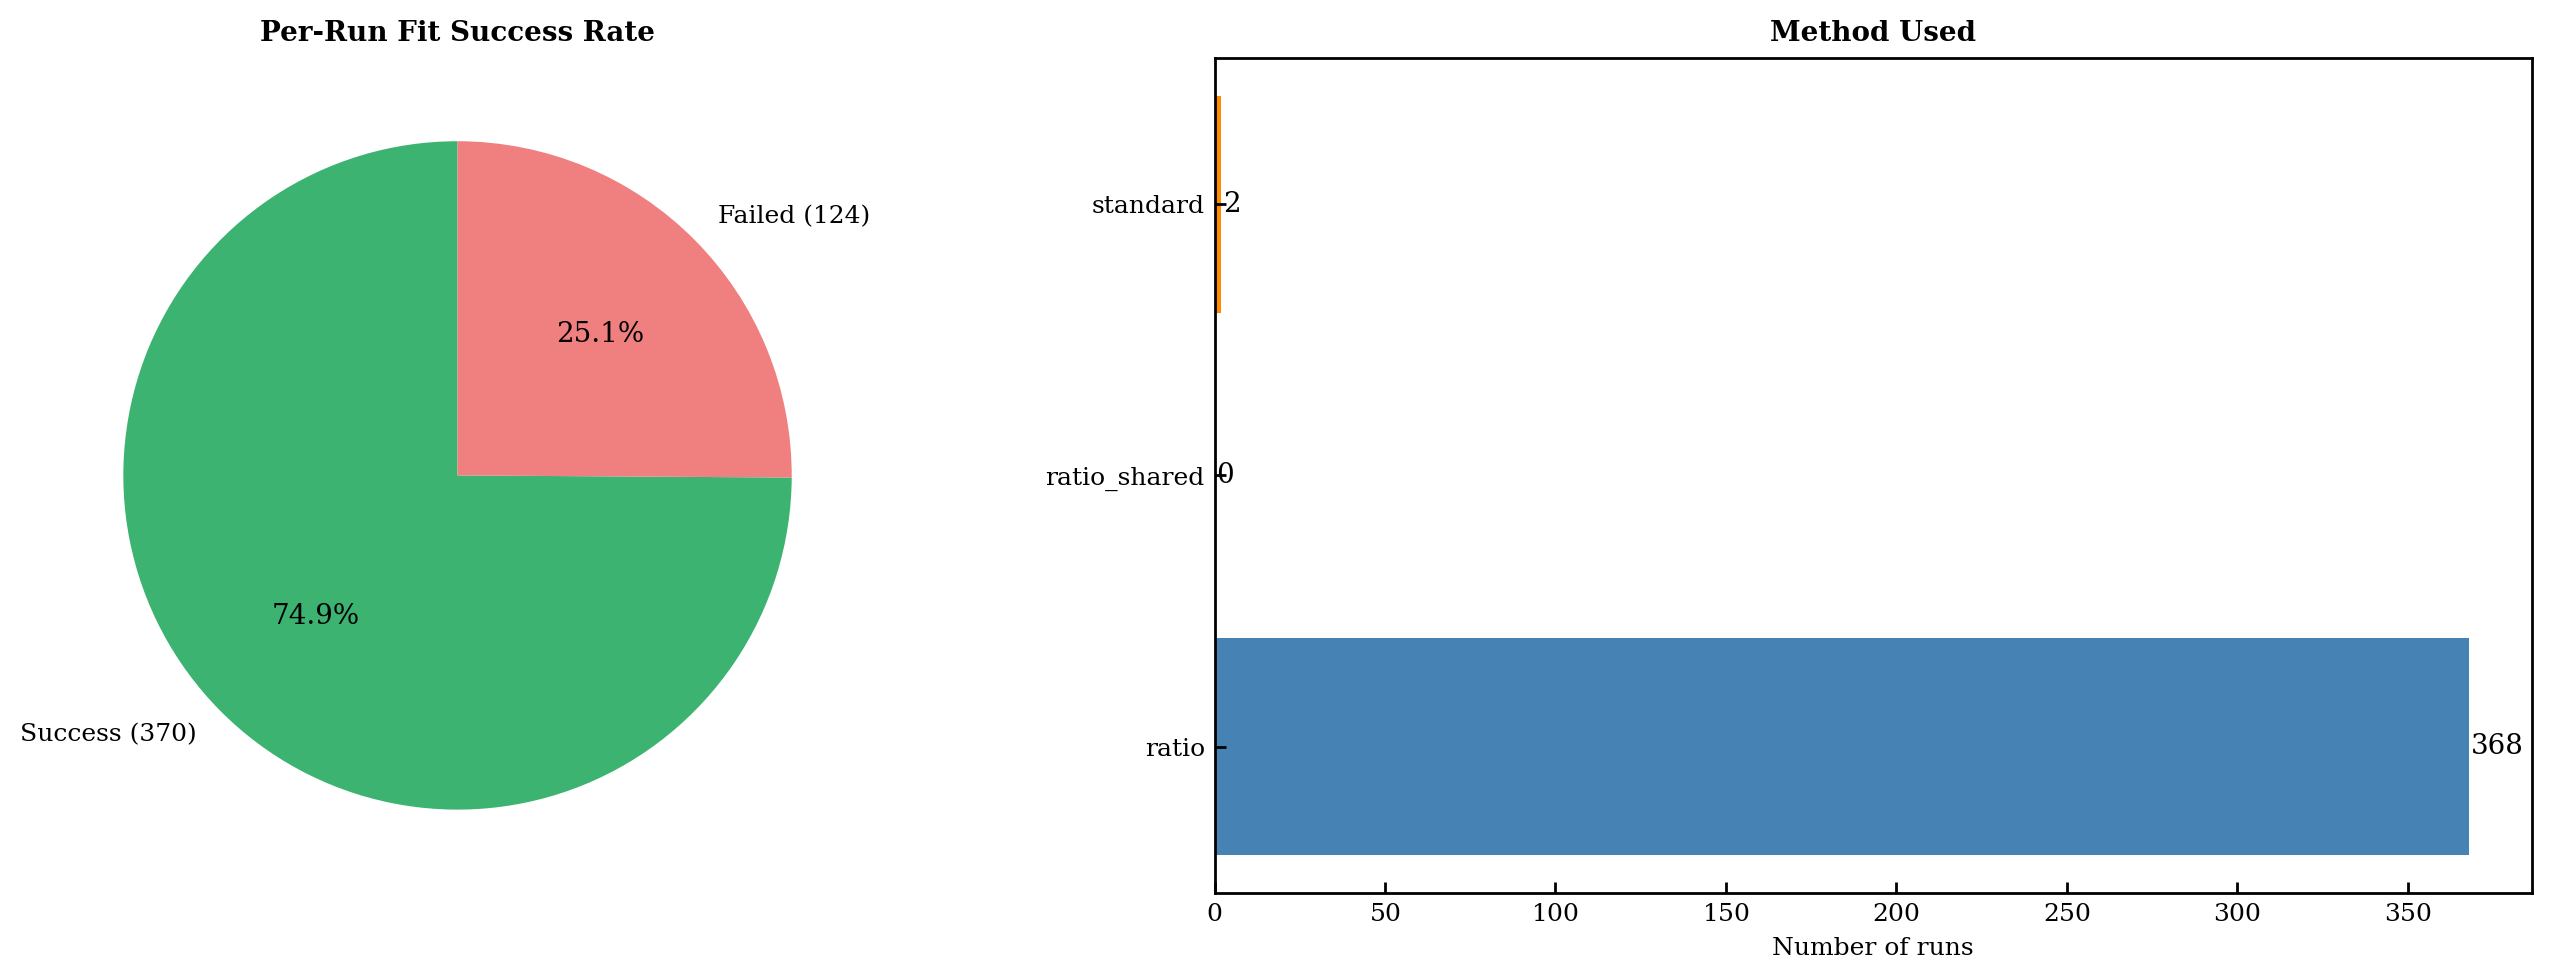

Total: 494  |  OK: 370 (74.9%)  |  Failed: 124


In [10]:
# ═══════════════════════════════════════════════════════════════
# SUCCESS RATE + METHOD BREAKDOWN
# ═══════════════════════════════════════════════════════════════

n_ok   = df_fits['success'].sum()
n_fail = len(df_fits) - n_ok

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie([n_ok, n_fail], labels=[f'Success ({n_ok})', f'Failed ({n_fail})'],
            colors=['mediumseagreen', 'lightcoral'], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Per-Run Fit Success Rate', fontweight='bold')

ok_df = df_fits[df_fits['success']]
methods = ['ratio', 'ratio_shared', 'standard']
counts  = [(ok_df['method']==m).sum() for m in methods]
colors  = ['steelblue', 'goldenrod', 'darkorange']
axes[1].barh(methods, counts, color=colors)
for i, c in enumerate(counts):
    axes[1].text(c + 0.5, i, str(c), va='center')
axes[1].set_xlabel('Number of runs')
axes[1].set_title('Method Used', fontweight='bold')
safe_tight(fig)
plt.show()
print(f'Total: {len(df_fits)}  |  OK: {n_ok} ({100*n_ok/len(df_fits):.1f}%)  |  Failed: {n_fail}')

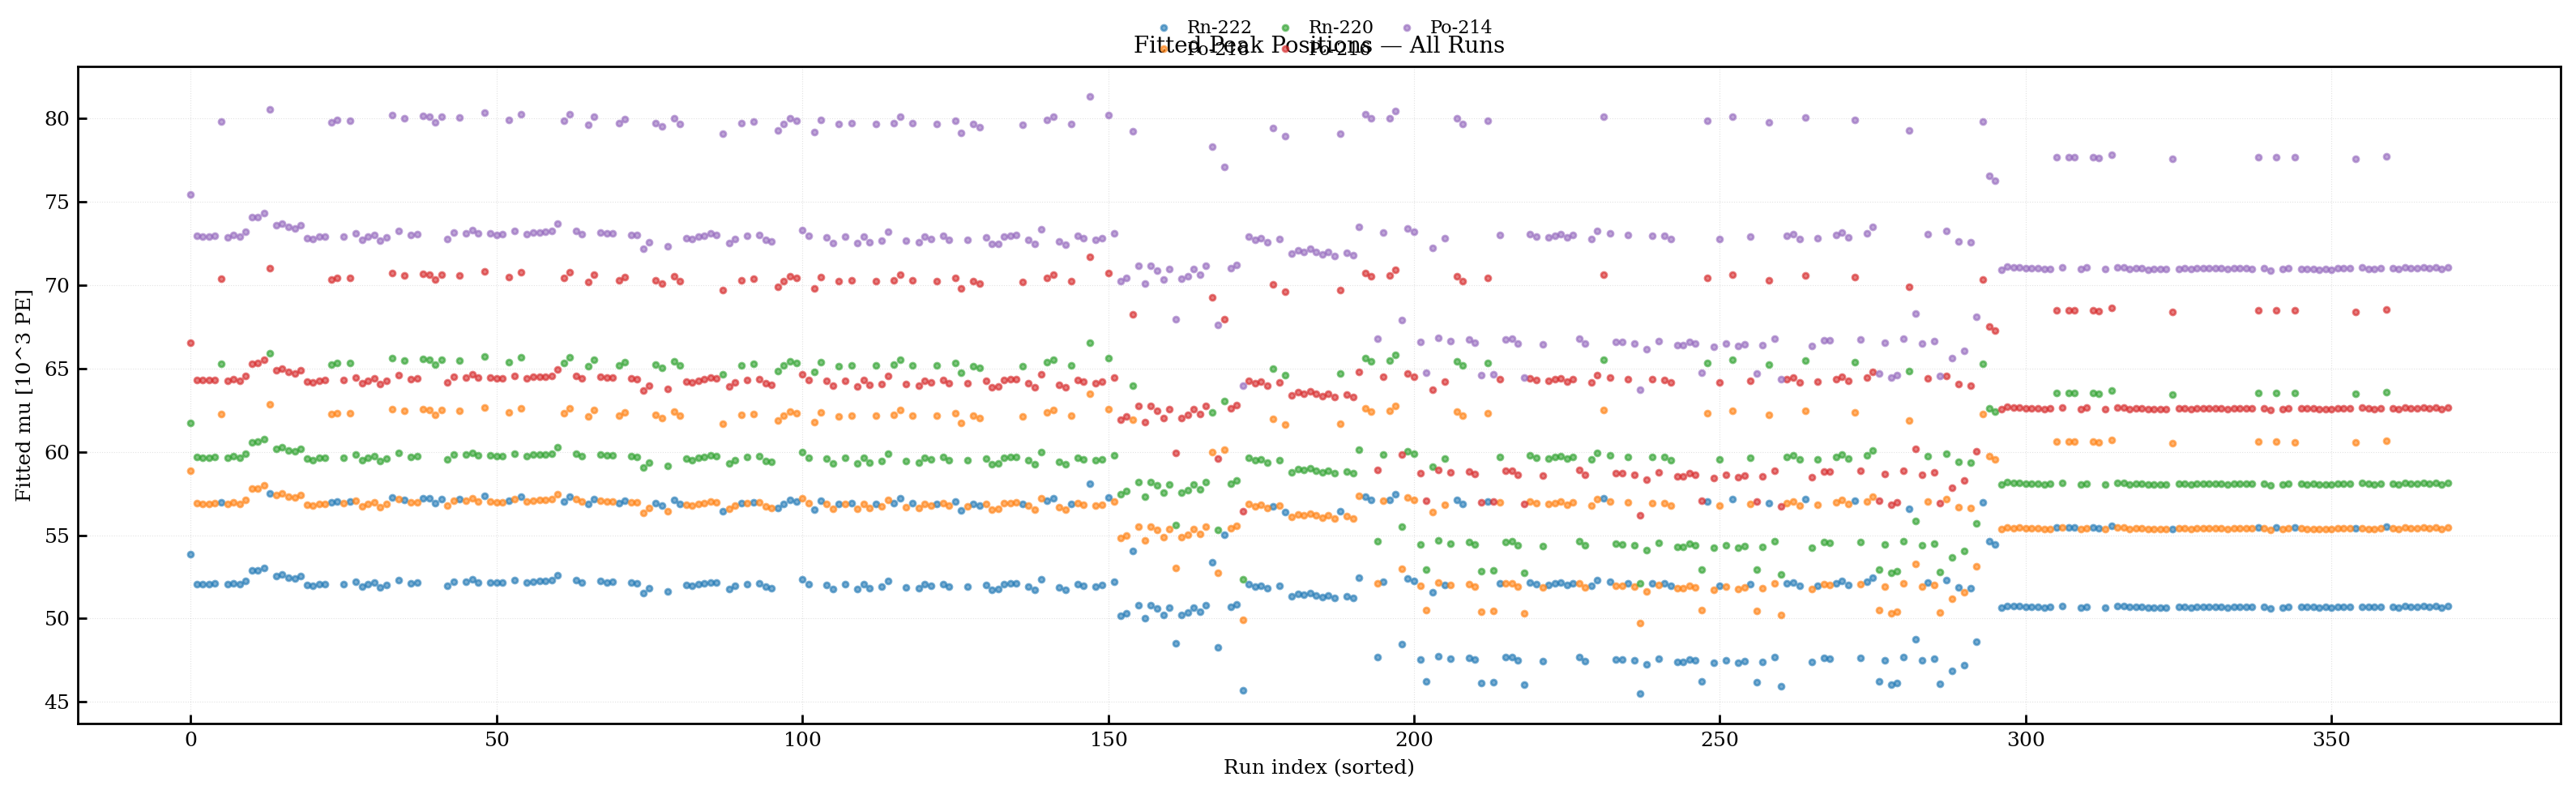

In [11]:
# ═══════════════════════════════════════════════════════════════
# FITTED mu vs RUN — all 5 isotopes
# ═══════════════════════════════════════════════════════════════

ok = df_fits[df_fits['success']].sort_values('run')
fig, ax = plt.subplots(figsize=(16, 5))
cmap = plt.cm.tab10
for i, name in enumerate(PEAK_NAMES):
    ax.plot(range(len(ok)), ok[f'fit_mu_{name}']/1e3, 'o',
            color=cmap(i), markersize=2.5, alpha=0.6, label=name)
ax.set_xlabel('Run index (sorted)')
ax.set_ylabel('Fitted mu [10^3 PE]')
ax.set_title('Fitted Peak Positions — All Runs')
ax.legend(ncol=3, fontsize=12)
ax.grid(True, alpha=0.3)
safe_tight(fig)
plt.show()

In [12]:
# ═══════════════════════════════════════════════════════════════
# FAILED RUNS LIST
# ═══════════════════════════════════════════════════════════════

failed = df_fits[~df_fits['success']]
if len(failed) > 0:
    print(f'{len(failed)} failed runs:')
    for _, r in failed.iterrows():
        g = f'{r["scale_guess_pe"]:.0f}' if pd.notna(r['scale_guess_pe']) else 'N/A'
        print(f'  {r["run"]:8s}  {int(r["n_events"]):5d} evts  '
              f'{r["status"]:25s}  guess={g}')
else:
    print('All runs fit successfully!')

124 failed runs:
  083645        0 evts  too_few_events(0)          guess=N/A
  083644        0 evts  too_few_events(0)          guess=N/A
  083643        0 evts  too_few_events(0)          guess=N/A
  083642        0 evts  too_few_events(0)          guess=N/A
  083641        0 evts  too_few_events(0)          guess=N/A
  083640        0 evts  too_few_events(0)          guess=N/A
  083639        0 evts  too_few_events(0)          guess=N/A
  083638        0 evts  too_few_events(0)          guess=N/A
  083637        0 evts  too_few_events(0)          guess=N/A
  083636        0 evts  too_few_events(0)          guess=N/A
  083635        0 evts  too_few_events(0)          guess=N/A
  083634        0 evts  too_few_events(0)          guess=N/A
  083633        0 evts  too_few_events(0)          guess=N/A
  083632        0 evts  too_few_events(0)          guess=N/A
  083631        0 evts  too_few_events(0)          guess=N/A
  083630        0 evts  too_few_events(0)          guess=N/A
  08362

In [14]:
# ═══════════════════════════════════════════════════════════════
# DEFINE PARTITIONS (time boundaries in Unix seconds)
# ═══════════════════════════════════════════════════════════════

def to_ts(date_str):
    return pd.Timestamp(date_str, tz='UTC').timestamp()

# Purifier-based partitions:
#   Apr 29: Q5 first installed
#   May 11: Q5 removed, ST707 installed
#   May 21: 2nd ST707, Q5 vessel empty
#   May 25-Jun 4: Q5 gone, ST707 cleaning residual Rn
#   Jun 5: Kr distillation started
#   Jun 8-9: Q5 refilled with new pellets, regenerated
#   Jun 11: Q5 vessel reinstalled, cooldown
#   Jun 12 ~18:00: Fresh Q5 back online in LXePUR loop
#   Jun 20: LXe level 4->5 mm; Jun 25: 5->5.7 mm
#   Jul 3: Q5 removed again (beyond data range)
partitions = [
    ('P1: OLD Q5',                    to_ts('2026-05-01'), to_ts('2026-05-11')),
    ('P2: ST707, Q5 removed',          to_ts('2026-05-11'), to_ts('2026-05-26')),
    ('P3: ST707, Q5 Rn cleaned',       to_ts('2026-05-26'), to_ts('2026-06-12')),
    ('P4: FRESH Q5',                   to_ts('2026-06-12'), to_ts('2026-07-02')),
]

def assign_partition(start_s):
    for name, t0, t1 in partitions:
        if t0 <= start_s < t1:
            return name
    return None

runs_sr3_indexed = runs_sr3.set_index('name')
df_fits['start_s'] = df_fits['run'].map(runs_sr3_indexed['start_s'])
df_fits['partition'] = df_fits['start_s'].apply(assign_partition)

print('Run counts per partition:')
print(df_fits['partition'].value_counts().sort_index())
for pname, t0, t1 in partitions:
    t0_ns, t1_ns = int(t0*1e9), int(t1*1e9)
    n = ((rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)).sum()
    print(f'  {pname}: {n:,} events')


Run counts per partition:
partition
P1: Q5 early (May 1–11)                 10
P2: ST707 (May 11–25)                  186
P3: NO purifier (May 25–Jun 5)         103
P5: LXe level changed (Jun 20–Jul2)     62
Name: count, dtype: int64
  P1: Q5 early (May 1–11): 24,537 events
  P2: ST707 (May 11–25): 119,346 events
  P3: NO purifier (May 25–Jun 5): 119,837 events
  P4: Distillation on (Jun 5–20): 0 events
  P5: LXe level changed (Jun 20–Jul2): 205,590 events


In [13]:
# ═══════════════════════════════════════════════════════════════
# ASYMMETRIC WINDOW HELPER — Po-218 / Rn-220 already removed
# With 3 peaks (Rn-222, Po-218, Po-214), standard ±2σ is fine
# ═══════════════════════════════════════════════════════════════

def _get_window(peak_idx, mu_i, sig_i, all_mu):
    return mu_i - 2.0 * sig_i, mu_i + 2.0 * sig_i

print('_get_window(): standard ±2σ (3 peaks, no overlap)')


_get_window() defined. Asymmetric window helper for Po-218/Rn-220 overlap.


In [ ]:
# PARTITION & EVENT VLINE HELPERS

def add_partition_vlines(ax, y_frac=0.95):
    """Black solid lines at partition boundaries (major purifier changes)."""
    events = [
        (to_ts('2026-05-11'), 'Q5 replaced'),
        (to_ts('2026-05-26'), 'Q5 Rn cleaned'),
        (to_ts('2026-06-12'), 'Q5 installed'),
    ]
    for ts, label in events:
        dt = datetime.fromtimestamp(ts, tz=timezone.utc)
        ax.axvline(x=dt, color='black', ls='-', lw=1.2, alpha=0.6)
        _, y_hi = ax.get_ylim()
        ax.text(dt, y_hi * y_frac, label, fontsize=7, color='black',
                rotation=90, va='top', ha='right', alpha=0.85)

def add_event_vlines(ax, y_frac=0.85):
    """Gray dashed lines at secondary events (gain-related)."""
    events = [
        (to_ts('2026-06-05'), 'Kr distillation'),
        (to_ts('2026-06-20'), 'LXe level'),
    ]
    for ts, label in events:
        dt = datetime.fromtimestamp(ts, tz=timezone.utc)
        ax.axvline(x=dt, color='gray', ls='--', lw=0.8, alpha=0.35)
        _, y_hi = ax.get_ylim()
        ax.text(dt, y_hi * y_frac, label, fontsize=6, color='gray',
                rotation=90, va='top', ha='right', alpha=0.7)

print('add_partition_vlines() + add_event_vlines() defined.')


In [15]:
# ═══════════════════════════════════════════════════════════════
# FIT MODEL — ratio-constrained (3 peaks, linear bg)
# ═══════════════════════════════════════════════════════════════
# mu_i = scale * Q_i / Q_Rn222  (all 3 peaks ratio-constrained)
# 3 amps + 1 scale + 3 sigmas + bg0 + bg_slope = 9 params

def model_ratio_constrained(x, *params):
    N = N_PEAKS
    bg0     = params[-2]
    bg_slope = params[-1]
    scale   = params[N]
    result  = (bg0 + bg_slope * (x - 60000) / 1000) * np.ones_like(x)
    for i in range(N):
        amp = params[i]
        sig = params[N + 1 + i]
        mu  = scale * PEAK_ENERGIES[i] / E_RN222
        result += amp * np.exp(-0.5 * ((x - mu) / sig)**2)
    return result

MODEL = model_ratio_constrained
print('MODEL = model_ratio_constrained (3 peaks, 9 params)')


model_semi_constrained() defined:
  Rn-222, Po-218, Rn-220: mu = scale * E_i/E_Rn222 (3 peaks constrained)
  Po-216, Po-214: mu free (corrects non-linear light yield)
  Linear bg, 16 params total


---
## Partition-Based Fit

Fit each partition with high statistics using an improved model:
- **Linear background** — helps high-energy peaks
- **Semi-constrained** means (Rn-222/Po-218/Rn-220 ratio-constrained, Po-216/Po-214 free)

| Partition | Dates | Purifier |
|-----------|-------|----------|
| P1: OLD Q5 | May 1–11 | Original Q5 |
| P2: ST707, Q5 removed | May 11–26 | ST707, Q5 Rn decaying |
| P3: ST707, Q5 cleaned | May 26–Jun 12 | ST707, Q5 Rn depleted |
| P4: FRESH Q5 | Jun 12–Jul 2 | New Q5 pellets |


In [16]:
# ═══════════════════════════════════════════════════════════════
# FIT SPECTRUM PER PARTITION
# ═══════════════════════════════════════════════════════════════

def fit_partition(events, partition_name, fit_range=(48e3, 80e3)):
    n_ev = len(events)
    if n_ev < 100:
        return {'p_fit': None, 'fit_mu': None, 'success': False, 'n_ev': n_ev}

    n_bins = min(800, max(200, n_ev // 10))
    counts, edges = np.histogram(events['area_2_corrected'], bins=n_bins, range=fit_range)
    centers = 0.5 * (edges[:-1] + edges[1:])
    y_err = np.sqrt(np.maximum(counts, 1))

    rn222_pe, guess_mu = find_peak_guess(events, n_bins)
    scale_guess = rn222_pe if rn222_pe is not None else 52000
    if guess_mu is None:
        guess_mu = 52000 * PEAK_ENERGIES / E_RN222

    N = N_PEAKS
    p0, lo, hi = [], [], []
    for mu0 in guess_mu:
        idx = np.argmin(np.abs(centers - mu0))
        p0.append(max(counts[idx]*0.4, 3))
        lo.append(0); hi.append(np.inf)
    p0.append(scale_guess); lo.append(scale_guess * 0.95); hi.append(scale_guess * 1.05)
    for _ in range(N):
        p0.append(800); lo.append(50); hi.append(8000)
    p0.append(1.0); lo.append(0);   hi.append(np.inf)
    p0.append(0.0); lo.append(-50); hi.append(50)

    try:
        p_fit, _ = curve_fit(MODEL, centers, counts,
                             p0=p0, sigma=y_err, bounds=(lo, hi), maxfev=50000)
        fit_mu = p_fit[N] * PEAK_ENERGIES / E_RN222
        if np.all((fit_mu > 40000) & (fit_mu < 85000)):
            print('  %s: OK, Rn-222 mu=%d PE (%d evts)' % (partition_name, int(fit_mu[0]), n_ev))
            return {'p_fit': p_fit, 'fit_mu': fit_mu, 'success': True,
                    'n_ev': n_ev, 'n_bins': n_bins}
    except Exception as e:
        pass

    print('  %s: FIT FAILED (%d events)' % (partition_name, n_ev))
    return {'p_fit': None, 'fit_mu': None, 'success': False, 'n_ev': n_ev}


partition_fits = {}
for pname, t0, t1 in partitions:
    t0_ns, t1_ns = int(t0*1e9), int(t1*1e9)
    evts = rn_events[(rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)]
    partition_fits[pname] = fit_partition(evts, pname)

print('\nDone.')


  P1: Q5 early (May 1–11): OK, mu=52080/Mu[3]=64873Mu[4]=73904 (24,537 evts)
  P2: ST707 (May 11–25): OK, mu=51748/Mu[3]=64129Mu[4]=73367 (119,346 evts)
  P3: NO purifier (May 25–Jun 5): OK, mu=52087/Mu[3]=64590Mu[4]=73909 (119,837 evts)
  P5: LXe level changed (Jun 20–Jul2): OK, mu=50629/Mu[3]=62853Mu[4]=71724 (205,590 evts)

Done.


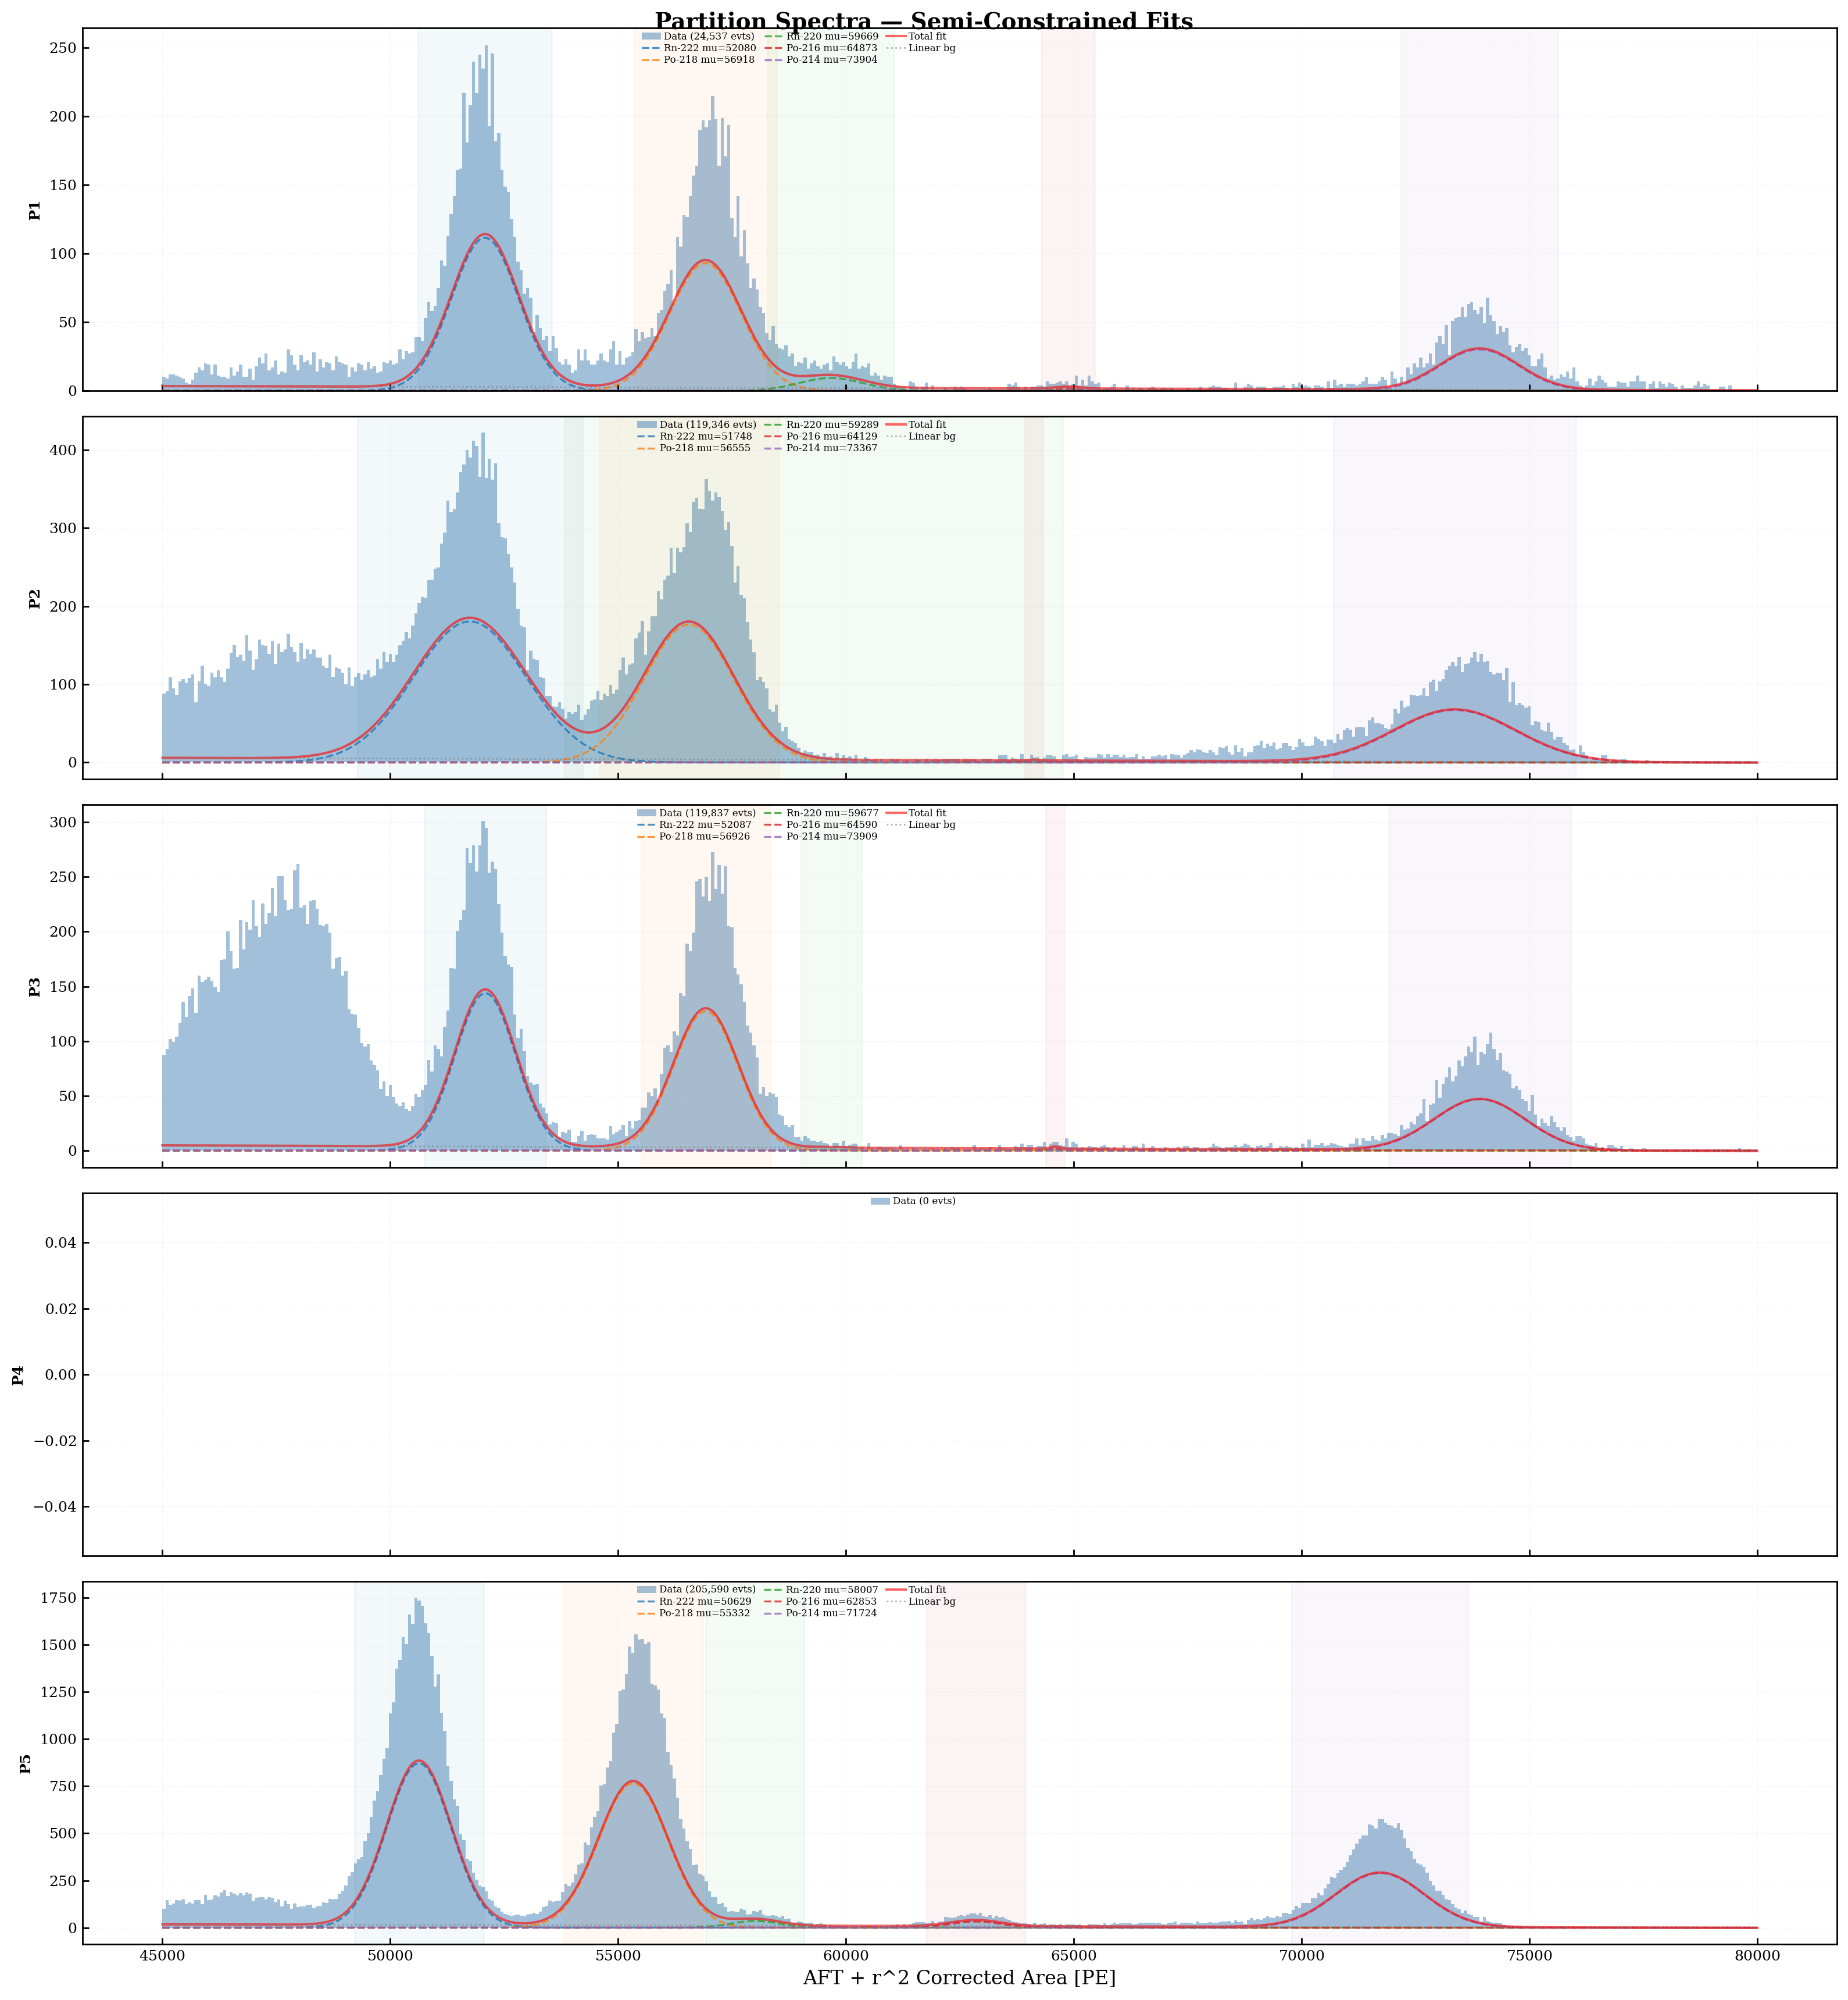

In [17]:
# ═══════════════════════════════════════════════════════════════
# PLOT PARTITION SPECTRA + FITS
# ═══════════════════════════════════════════════════════════════

n_part = len(partitions)
fig, axes = plt.subplots(n_part, 1, figsize=(16, 3.5 * n_part), sharex=True)
if n_part == 1: axes = [axes]

x_fine = np.linspace(45e3, 80e3, 2000)
cmap = plt.cm.tab10
N = N_PEAKS

for ax, (pname, t0, t1) in zip(axes, partitions):
    t0_ns, t1_ns = int(t0*1e9), int(t1*1e9)
    evts = rn_events[(rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)]
    n_bins = min(500, max(100, len(evts)//10))
    hc, he, _ = ax.hist(evts['area_2_corrected'], bins=n_bins, range=[45e3, 80e3],
                         color='steelblue', alpha=0.5, label=f'Data ({len(evts):,} evts)')

    res = partition_fits.get(pname)
    if res and res['success']:
        p = res['p_fit']; fit_mu = res['fit_mu']
        for i, name in enumerate(PEAK_NAMES):
            mu, sig = fit_mu[i], p[N + 1 + i]
            g = p[i] * np.exp(-0.5 * ((x_fine - mu) / sig)**2)
            ax.plot(x_fine, g, '--', color=cmap(i), lw=1.2, alpha=0.8,
                    label=f'{name} mu={mu:.0f}')
            ax.axvspan(mu - 2*sig, mu + 2*sig, color=cmap(i), alpha=0.05)
        y_tot = MODEL(x_fine, *p)
        bg = p[-2] + p[-1] * (x_fine - 60000) / 1000
        ax.plot(x_fine, y_tot, 'r-', lw=1.5, alpha=0.6, label='')
        ax.plot(x_fine, bg, 'gray', lw=1, ls=':', alpha=0.6, label='Linear bg')

    ax.set_ylabel(pname.split(':')[0], fontsize=9, fontweight='bold')
    ax.legend(fontsize=9, loc='upper right', ncol=3)
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel('AFT + r^2 Corrected Area [PE]', fontsize=12)
fig.suptitle('Partition Spectra — Semi-Constrained Fits', fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()


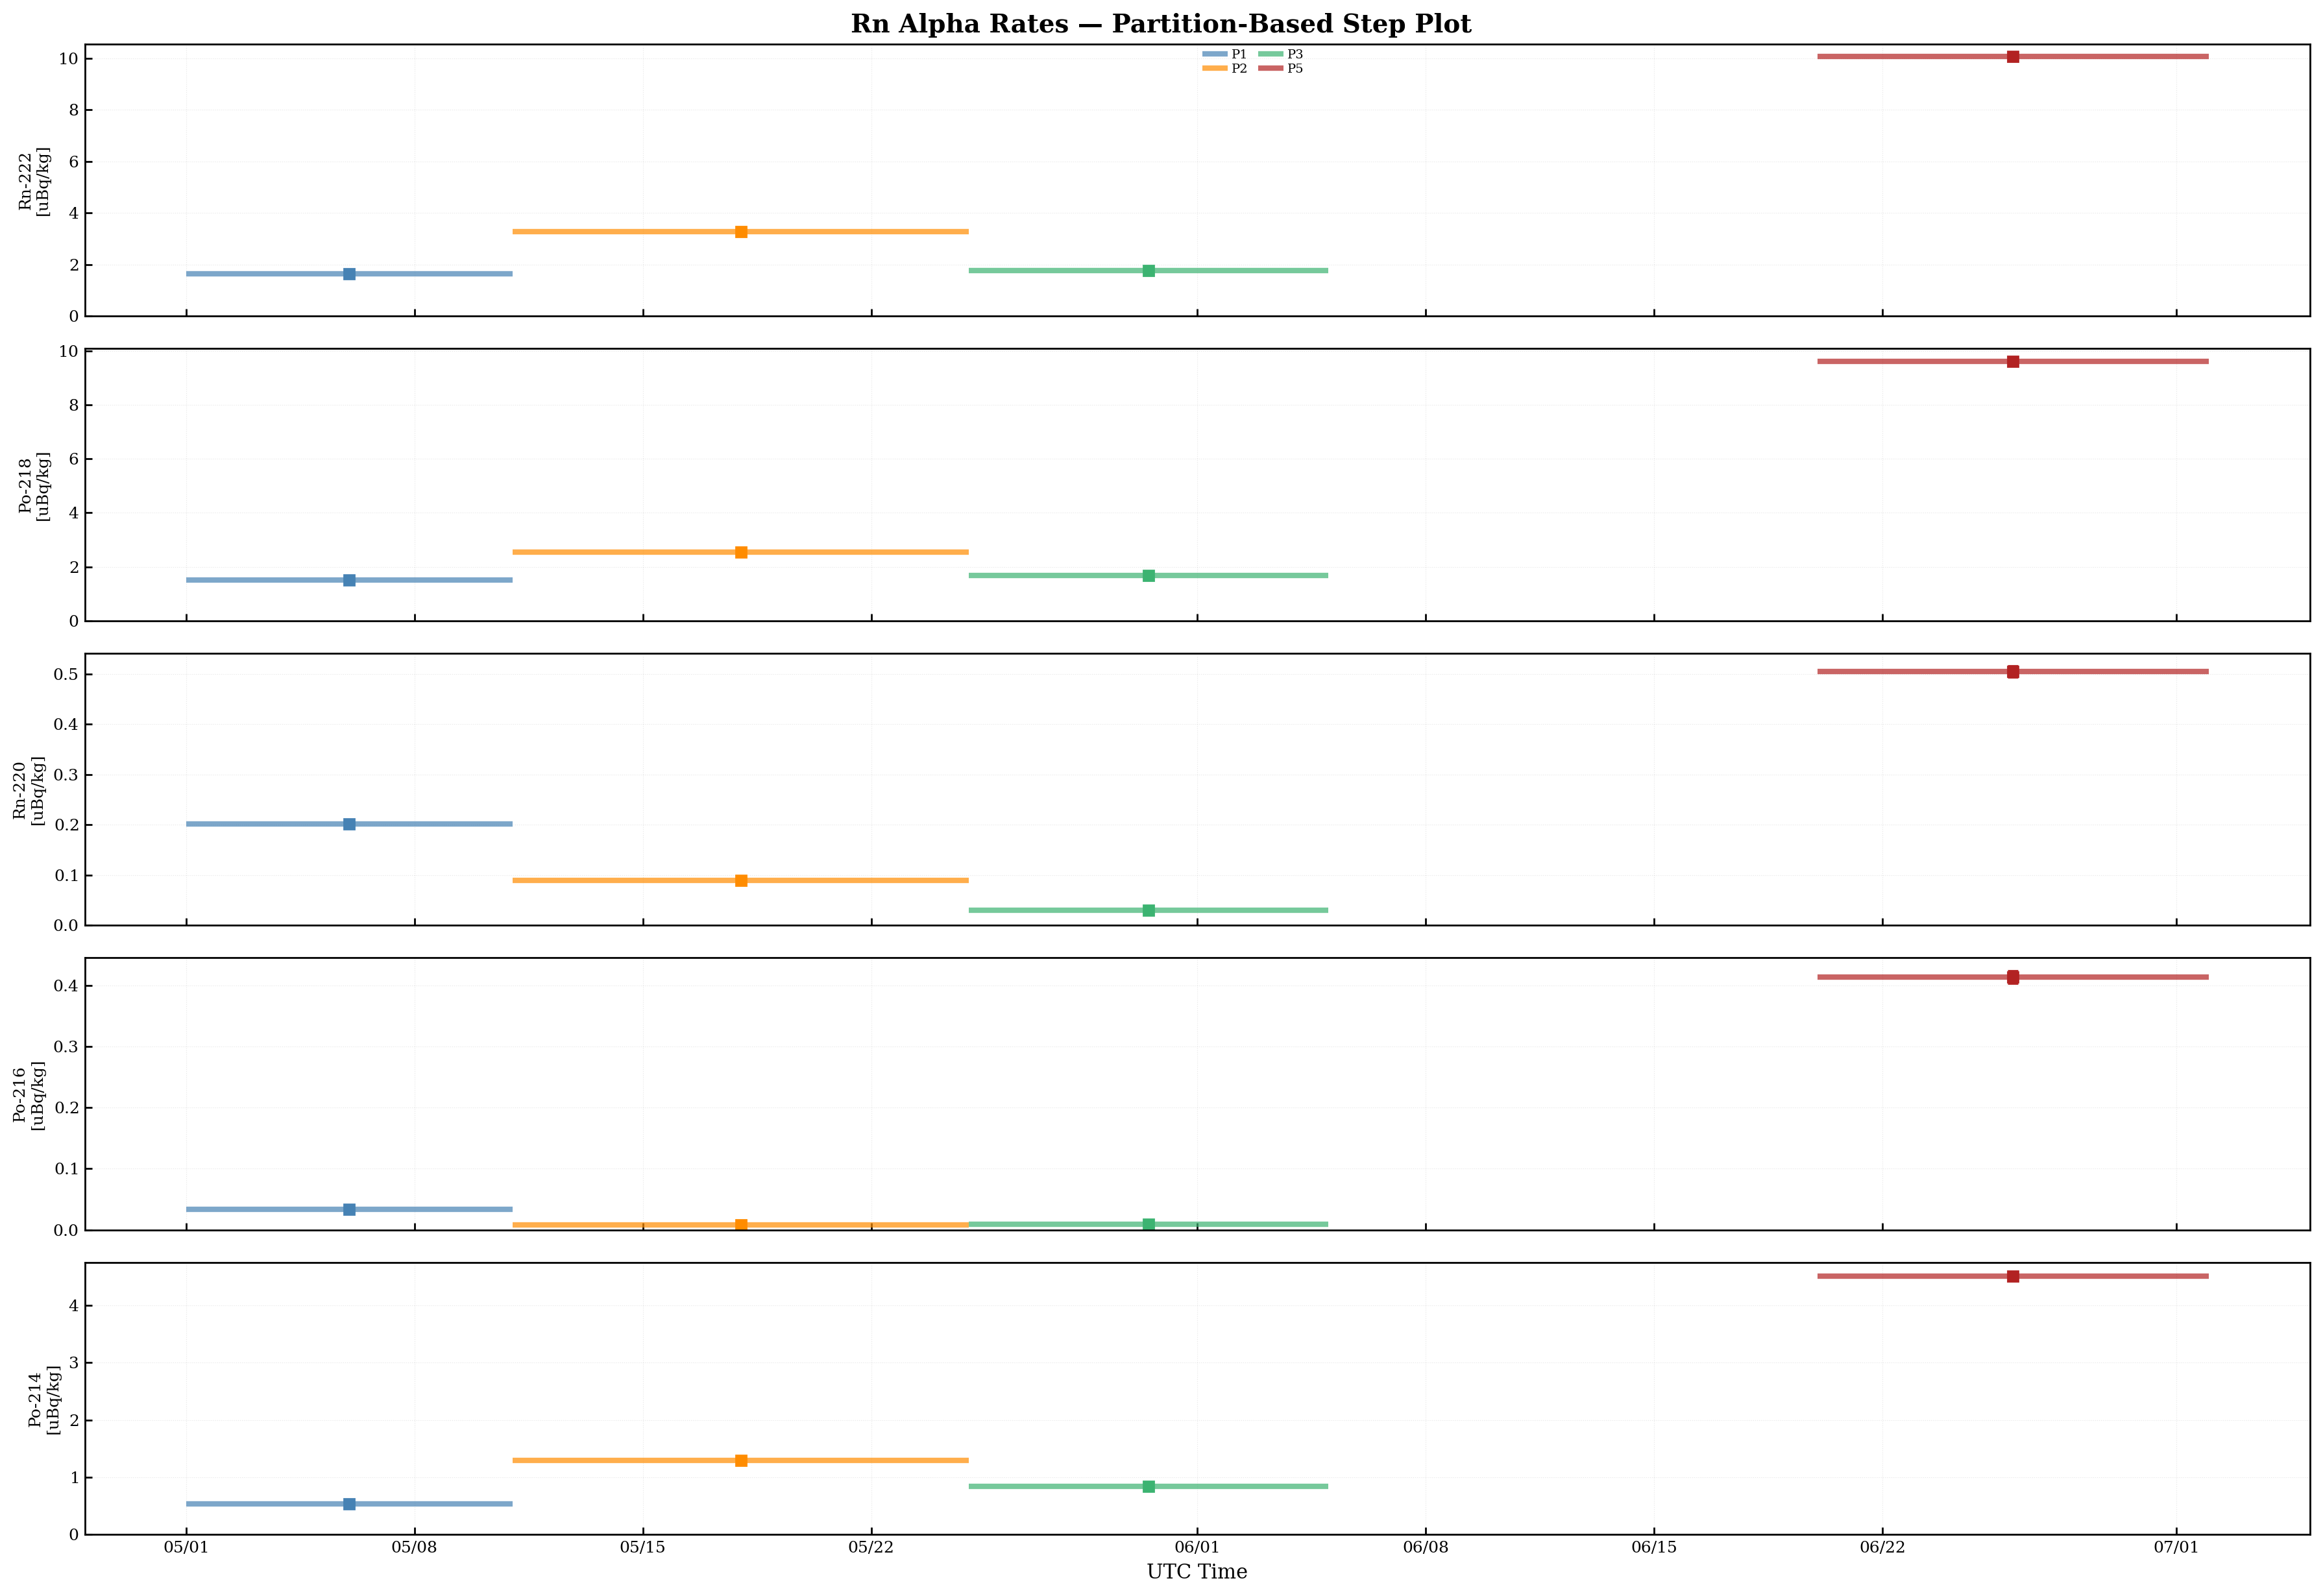

P1: Q5 early (May 1–11)                 Rn-222         5221 evts    1.65 +/- 0.02 uBq/kg  mu=52079
P1: Q5 early (May 1–11)                 Po-218         4745 evts    1.50 +/- 0.02 uBq/kg  mu=56917
P1: Q5 early (May 1–11)                 Rn-220          636 evts    0.20 +/- 0.01 uBq/kg  mu=59668
P1: Q5 early (May 1–11)                 Po-216          107 evts    0.03 +/- 0.00 uBq/kg  mu=64873
P1: Q5 early (May 1–11)                 Po-214         1694 evts    0.54 +/- 0.01 uBq/kg  mu=73903
P2: ST707 (May 11–25)                   Rn-222        14463 evts    3.27 +/- 0.03 uBq/kg  mu=51748
P2: ST707 (May 11–25)                   Po-218        11245 evts    2.54 +/- 0.02 uBq/kg  mu=56555
P2: ST707 (May 11–25)                   Rn-220          395 evts    0.09 +/- 0.00 uBq/kg  mu=59288
P2: ST707 (May 11–25)                   Po-216           35 evts    0.01 +/- 0.00 uBq/kg  mu=64129
P2: ST707 (May 11–25)                   Po-214         5726 evts    1.29 +/- 0.02 uBq/kg  mu=73366
P3: NO pur

In [18]:
# ═══════════════════════════════════════════════════════════════
# STEP PLOT — partition-fit rates
# ═══════════════════════════════════════════════════════════════

N_SIGMA = 2
FMASS = 3660.0

part_rates = []
for pname, t0_s, t1_s in partitions:
    res = partition_fits.get(pname)
    if not res or not res['success']:
        continue
    p, N = res['p_fit'], N_PEAKS
    t0_ns, t1_ns = int(t0_s*1e9), int(t1_s*1e9)
    evts = rn_events[(rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)]
    lt = t1_s - t0_s
    for i, name in enumerate(PEAK_NAMES):
        mu, sig = res['fit_mu'][i], p[N + 1 + i]
        lo, hi = _get_window(i, mu, sig, res['fit_mu'])
        n = ((evts['area_2_corrected'] >= lo) & (evts['area_2_corrected'] <= hi)).sum()
        part_rates.append({
            'partition': pname, 't0_s': t0_s, 't1_s': t1_s,
            'isotope': name, 'n_events': n,
            'rate_ukgb': n/lt*1e6/FMASS,
            'rate_err_ukgb': np.sqrt(max(n,1))/lt*1e6/FMASS,
            'mu_pe': mu, 'sigma_pe': sig})

df_part_rates = pd.DataFrame(part_rates) if part_rates else pd.DataFrame()

if len(df_part_rates) > 0:
    import matplotlib.dates as mdates
    fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
    if N_PEAKS == 1: axes = [axes]
    pcolors = ['steelblue', 'darkorange', 'mediumseagreen', 'firebrick', 'purple']
    seen = set()
    for ax, name in zip(axes, PEAK_NAMES):
        di = df_part_rates[df_part_rates['isotope'] == name]
        for idx, (_, r) in enumerate(di.iterrows()):
            t0 = datetime.fromtimestamp(r['t0_s'], tz=timezone.utc)
            t1 = datetime.fromtimestamp(r['t1_s'], tz=timezone.utc)
            t_mid = t0 + (t1 - t0) / 2
            ps = r['partition'].split(':')[0].strip()
            c = pcolors[idx % len(pcolors)]
            lbl = ps if ps not in seen else None
            if lbl is not None: seen.add(ps)
            ax.hlines(r['rate_ukgb'], t0, t1, colors=c, lw=3, alpha=0.7, label=lbl)
            ax.errorbar(t_mid, r['rate_ukgb'], yerr=r['rate_err_ukgb'],
                        fmt='s', color=c, markersize=6, capsize=0, lw=1.5)
        ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
        ax.legend(fontsize=10, loc='upper left')
        ax.grid(True, alpha=0.25); ax.set_ylim(bottom=0)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
    axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
    axes[-1].set_xlabel('UTC Time', fontsize=11)
    fig.autofmt_xdate(rotation=0, ha='center')
    fig.suptitle('Rn Alpha Rates — Partition-Based Step Plot', fontsize=14, fontweight='bold')
    safe_tight(fig); plt.show()

    # Table
    for _, r in df_part_rates.iterrows():
        print('%-38s  %-10s  %7d evts  %6.2f +/- %.2f uBq/kg  mu=%d' % (
            r['partition'], r['isotope'], int(r['n_events']),
            r['rate_ukgb'], r['rate_err_ukgb'], int(r['mu_pe'])))
else:
    print('No successful partition fits.')


---
## Method 1: Run-by-Run Fit Rates

Rates extracted from the per-run 5-Gaussian fit (`df_fits`). Uses fitted mu/sigma per run (±2σ window).

In [19]:
# ═══════════════════════════════════════════════════════════════
# METHOD 1: Per-run rate extraction
# ═══════════════════════════════════════════════════════════════

N_SIGMA = 2
FMASS = 3660.0

results_m1 = []
for _, row in df_fits.iterrows():
    run_name = row['run']
    if not row['success']:
        continue
    rrow = runs_sr3[runs_sr3['name'] == run_name]
    if len(rrow) == 0: continue
    rrow = rrow.iloc[0]
    t0 = int(rrow['start_s'] * 1e9)
    t1 = int(float(rrow['end'].timestamp()) * 1e9)
    lt = rrow.get('duration', t1/1e9 - t0/1e9)
    evts = rn_events[(rn_events['time'] >= t0) & (rn_events['time'] < t1)]
    for i, name in enumerate(PEAK_NAMES):
        mu, sig = row[f'fit_mu_{name}'], row[f'fit_sigma_{name}']
        if np.isnan(mu) or np.isnan(sig): continue
        lo, hi = mu - N_SIGMA*sig, mu + N_SIGMA*sig
        n = ((evts['area_2_corrected'] >= lo) & (evts['area_2_corrected'] <= hi)).sum()
        results_m1.append({
            'run': run_name, 'start_s': rrow['start_s'],
            'end_s': float(rrow['end'].timestamp()), 'livetime_s': lt,
            'isotope': name, 'n_events': n,
            'rate_ukgb': n/lt*1e6/FMASS,
            'rate_err_ukgb': np.sqrt(max(n,1))/lt*1e6/FMASS})

df_m1 = pd.DataFrame(results_m1)
print(f'M1 rates: {len(df_m1)} rows ({df_m1["run"].nunique()} runs x {N_PEAKS} isotopes)')

M1 rates: 1850 rows (370 runs x 5 isotopes)


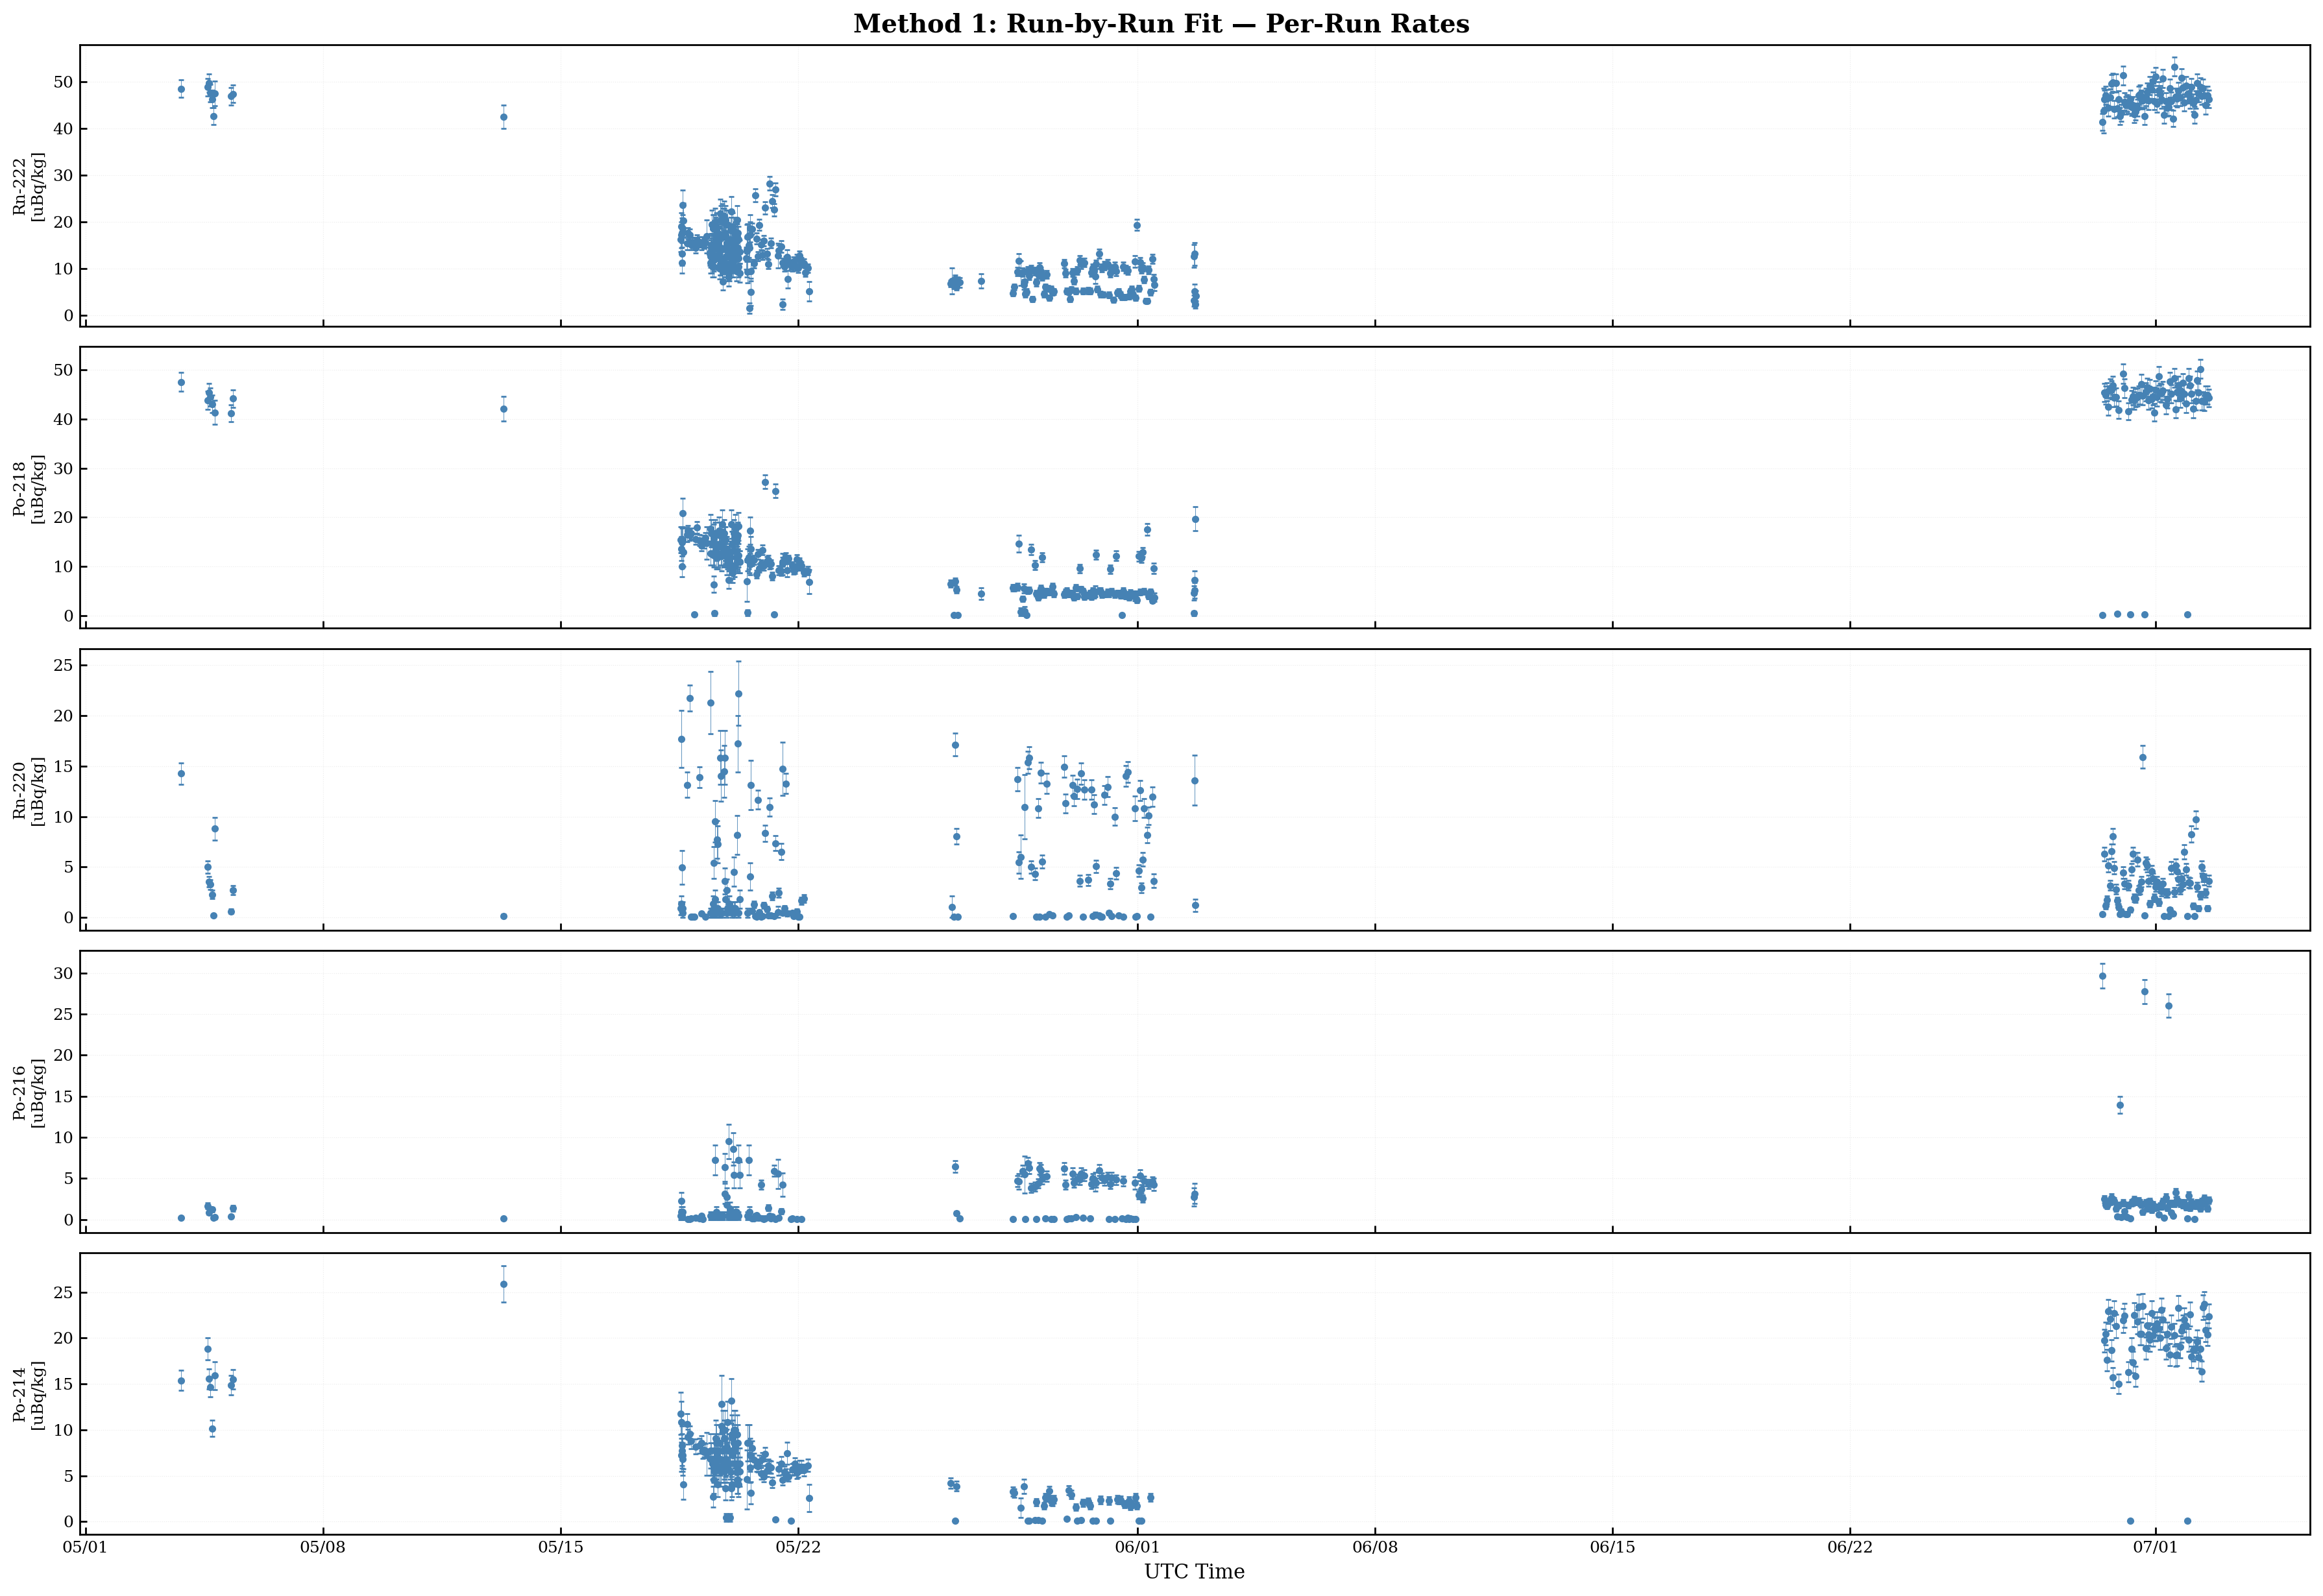

In [20]:
# M1 SCATTER — per-run errorbar, source-colored + vlines

import matplotlib.dates as mdates

SOURCE_COLORS = {'S1-only': 'steelblue', 'S1+S2': 'darkorange'}

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]

for ax, name in zip(axes, PEAK_NAMES):
    di = df_m1[(df_m1['isotope'] == name) & (df_m1['rate_ukgb'] > 0)]
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=1.5, capsize=0, lw=0.2)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.grid(True, alpha=0.2)
    add_partition_vlines(ax); add_event_vlines(ax)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Method 1: Run-by-Run Fit — Per-Run Rates', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


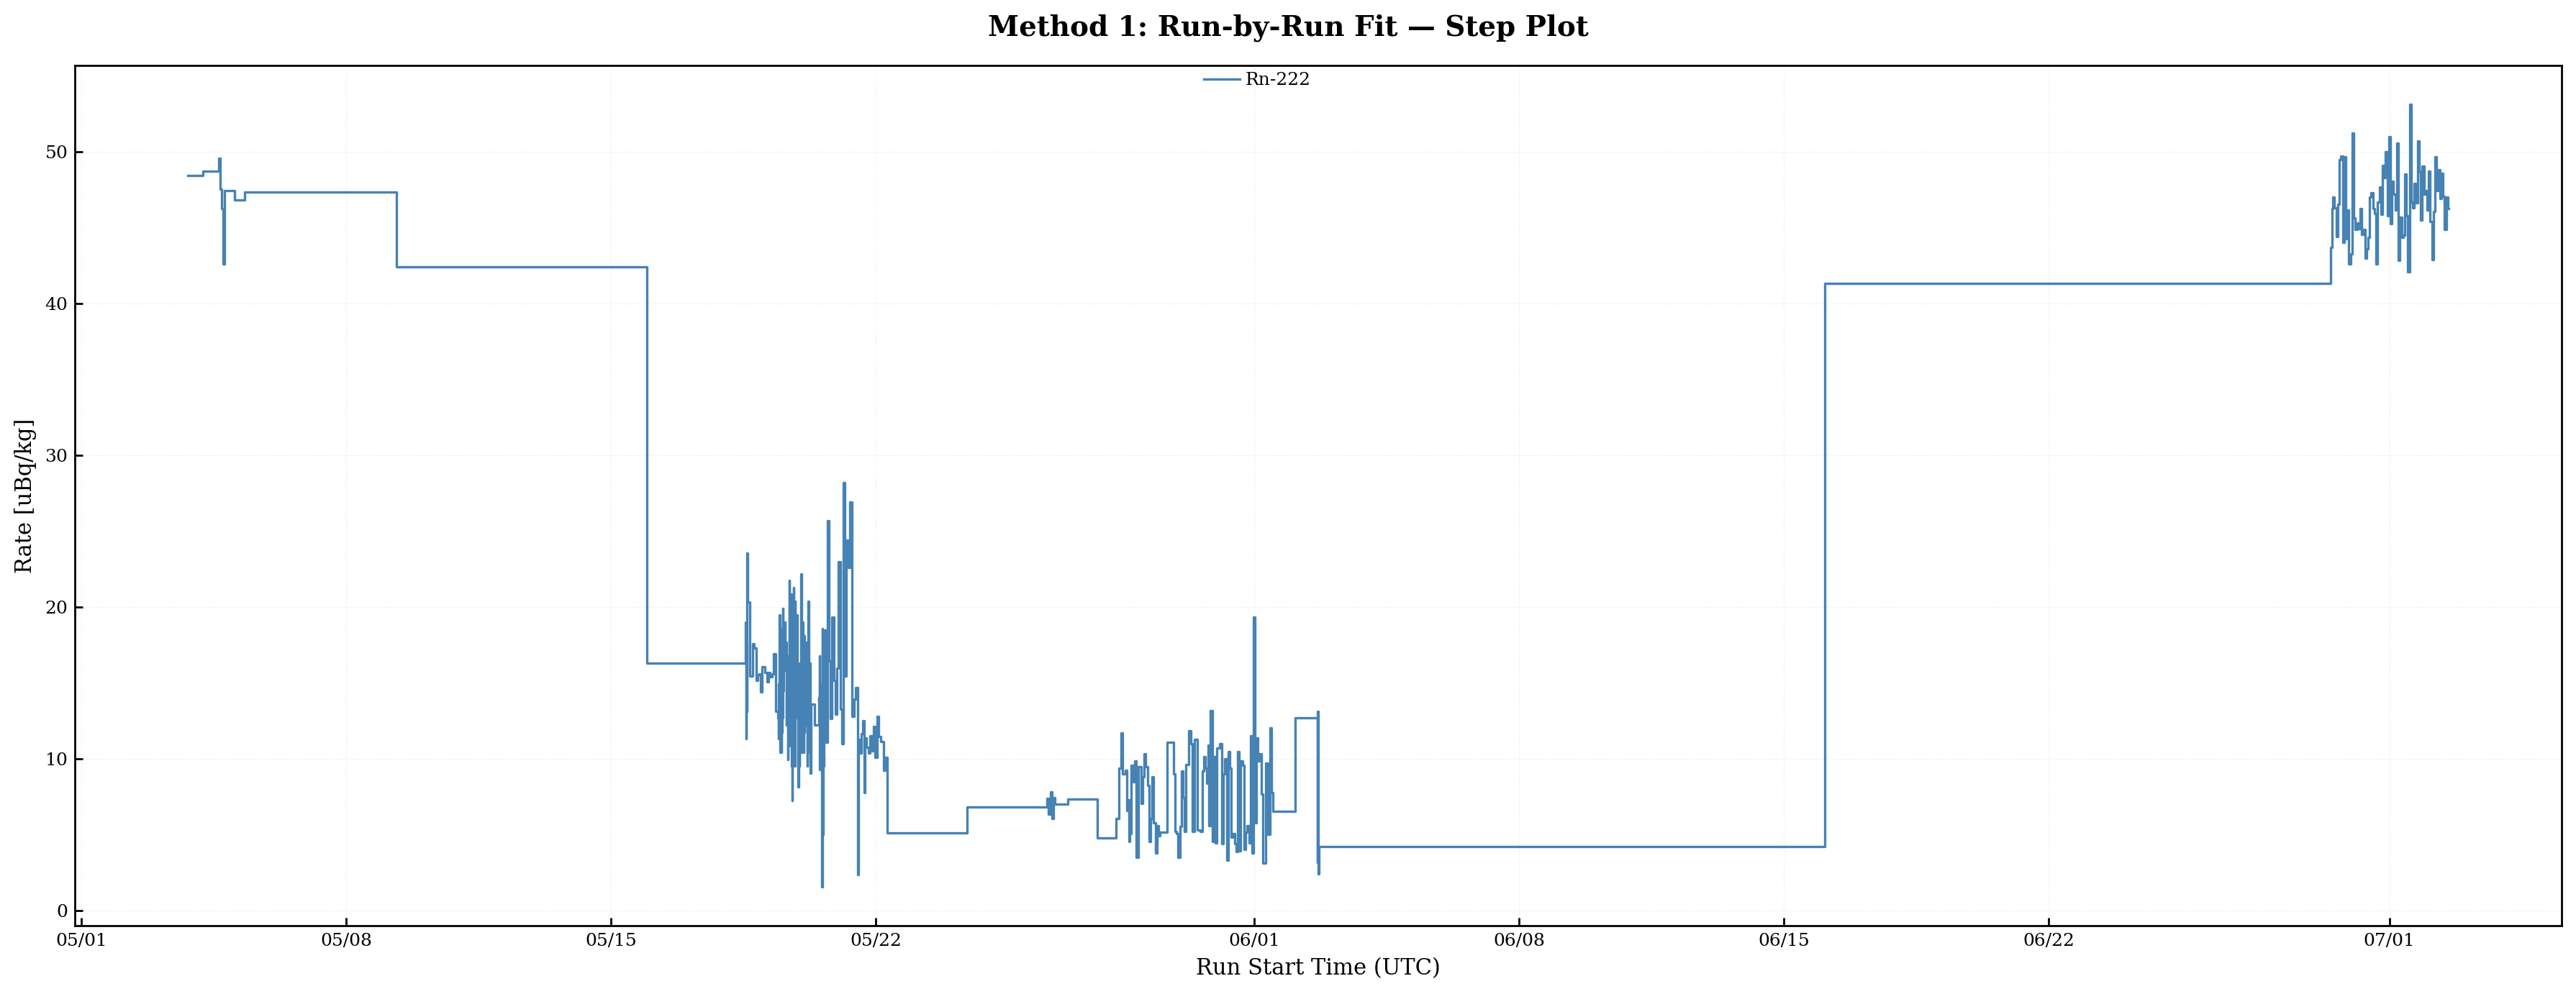

In [21]:
# M1 STEP — select isotopes + vlines

PLOT_ISOTOPES = ["Rn-222"]

iso_list = [n for n in PLOT_ISOTOPES if n in df_m1["isotope"].unique()]
fig, ax = plt.subplots(figsize=(18, 7))
for name in iso_list:
    di = df_m1[df_m1["isotope"] == name].sort_values("start_s")
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di["start_s"]]
    ax.step(sd, di["rate_ukgb"].values, where="mid", color=STEP_COLORS[name], lw=1.2, label=name)

add_partition_vlines(ax); add_event_vlines(ax)
ax.set_ylabel("Rate [uBq/kg]", fontsize=11)
ax.legend(fontsize=9, loc="upper right", ncol=len(iso_list))
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d", tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel("Run Start Time (UTC)", fontsize=11)
fig.autofmt_xdate(rotation=0, ha="center")
fig.suptitle("Method 1: Run-by-Run Fit — Step Plot", fontsize=14, fontweight="bold")
safe_tight(fig); plt.show()


---
## Method 2: Partition-Based Fit Rates

Uses partition-fit mu/sigma (ratio-constrained + linear bg) to count per-run events. More stable for low-statistics runs.

In [22]:
# Ensure df_fits has start_s + partition
df_fits['start_s'] = df_fits['run'].map(runs_sr3_indexed['start_s'])
df_fits['partition'] = df_fits['start_s'].apply(assign_partition)

results_m2 = []
for _, row in df_fits.iterrows():
    run_name = row['run']
    pname = row['partition']
    if pname is None: continue
    pfit = partition_fits.get(pname)
    if not pfit or not pfit['success']: continue
    rrow = runs_sr3[runs_sr3['name'] == run_name]
    if len(rrow) == 0: continue
    rrow = rrow.iloc[0]
    t0 = int(rrow['start_s'] * 1e9)
    t1 = int(float(rrow['end'].timestamp()) * 1e9)
    lt = rrow.get('duration', t1/1e9 - t0/1e9)
    evts = rn_events[(rn_events['time'] >= t0) & (rn_events['time'] < t1)]
    p, N = pfit['p_fit'], N_PEAKS
    for i, name in enumerate(PEAK_NAMES):
        mu, sig = pfit['fit_mu'][i], p[N + 1 + i]
        lo, hi = _get_window(i, mu, sig, pfit['fit_mu'])
        n = ((evts['area_2_corrected'] >= lo) & (evts['area_2_corrected'] <= hi)).sum()
        results_m2.append({
            'run': run_name, 'start_s': rrow['start_s'],
            'end_s': float(rrow['end'].timestamp()), 'livetime_s': lt,
            'isotope': name, 'n_events': n, 'partition': pname,
            'rate_ukgb': n/lt*1e6/FMASS,
            'rate_err_ukgb': np.sqrt(max(n,1))/lt*1e6/FMASS})

df_m2 = pd.DataFrame(results_m2)
print(f'M2 rates: {len(df_m2)} rows ({df_m2["run"].nunique()} runs x {N_PEAKS} isotopes)')


M2 rates: 1805 rows (361 runs x 5 isotopes)


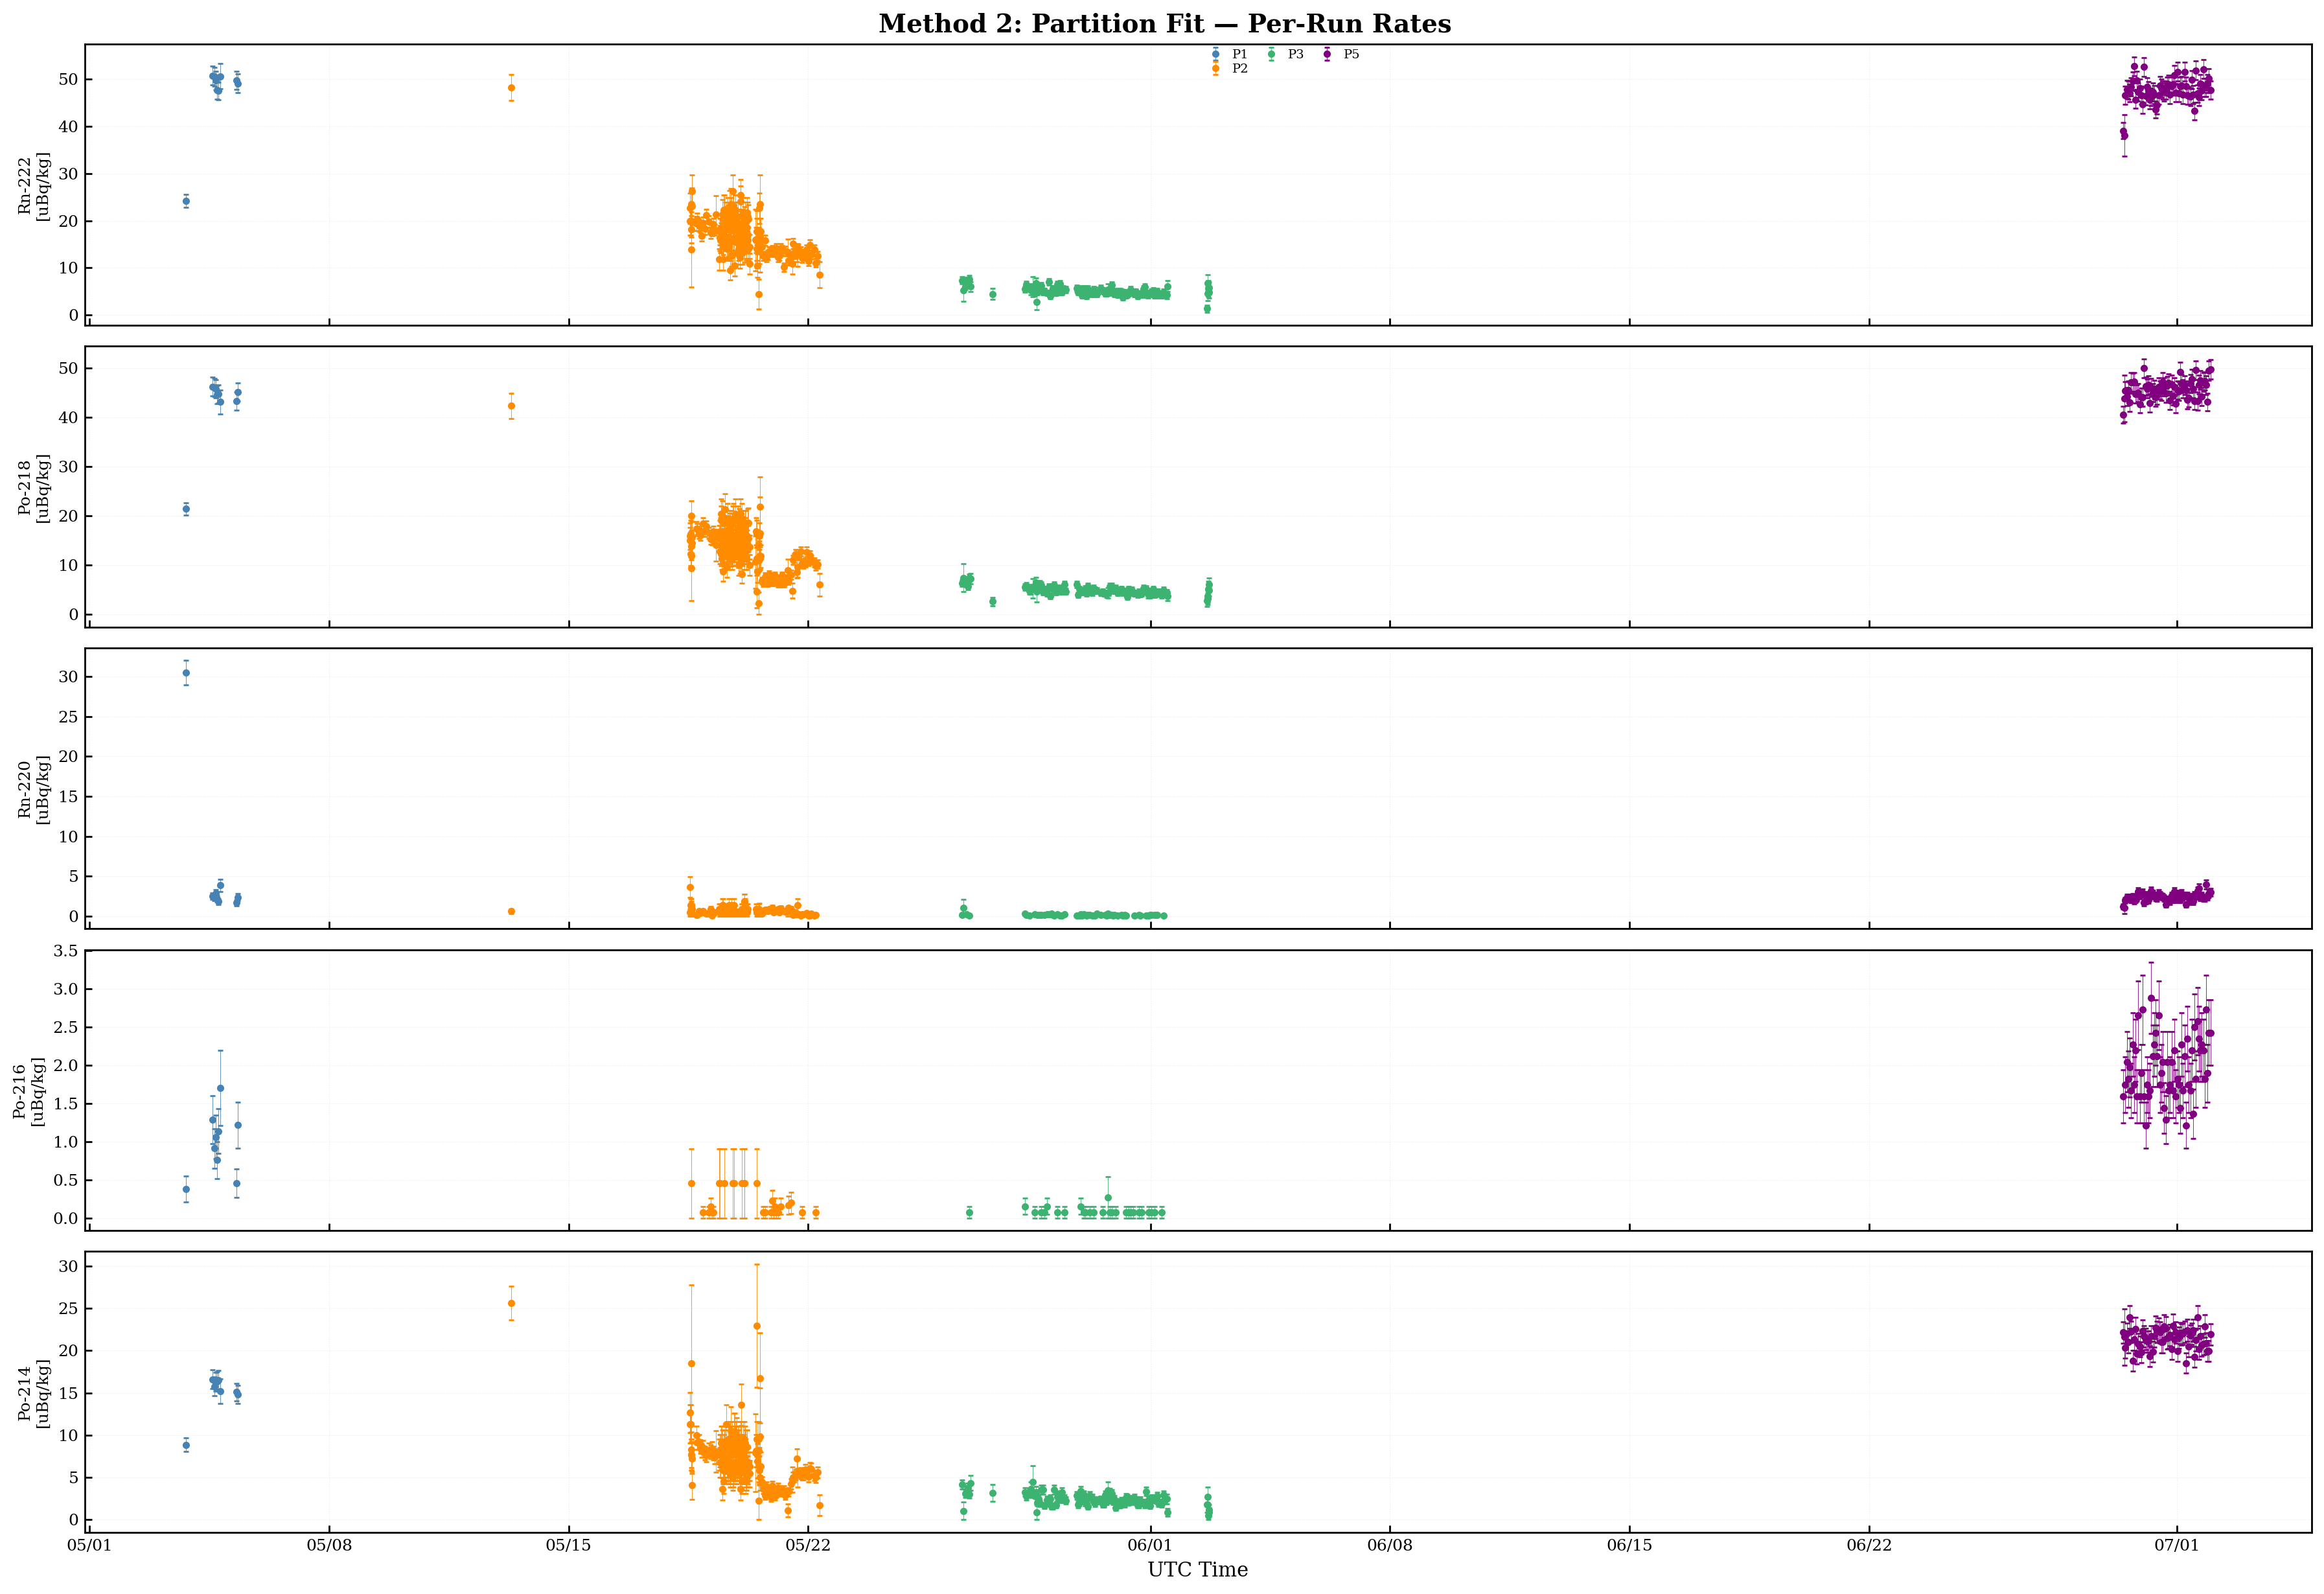

In [23]:
# M2 SCATTER — per-run errorbar, source-colored + vlines

SOURCE_COLORS = {'S1-only': 'steelblue', 'S1+S2': 'darkorange'}

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]
for ax, name in zip(axes, PEAK_NAMES):
    di = df_m2[(df_m2['isotope'] == name) & (df_m2['rate_ukgb'] > 0)]
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=1.5, capsize=0, lw=0.2)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.grid(True, alpha=0.2)
    add_partition_vlines(ax); add_event_vlines(ax)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Method 2: Partition Fit — Per-Run Rates', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


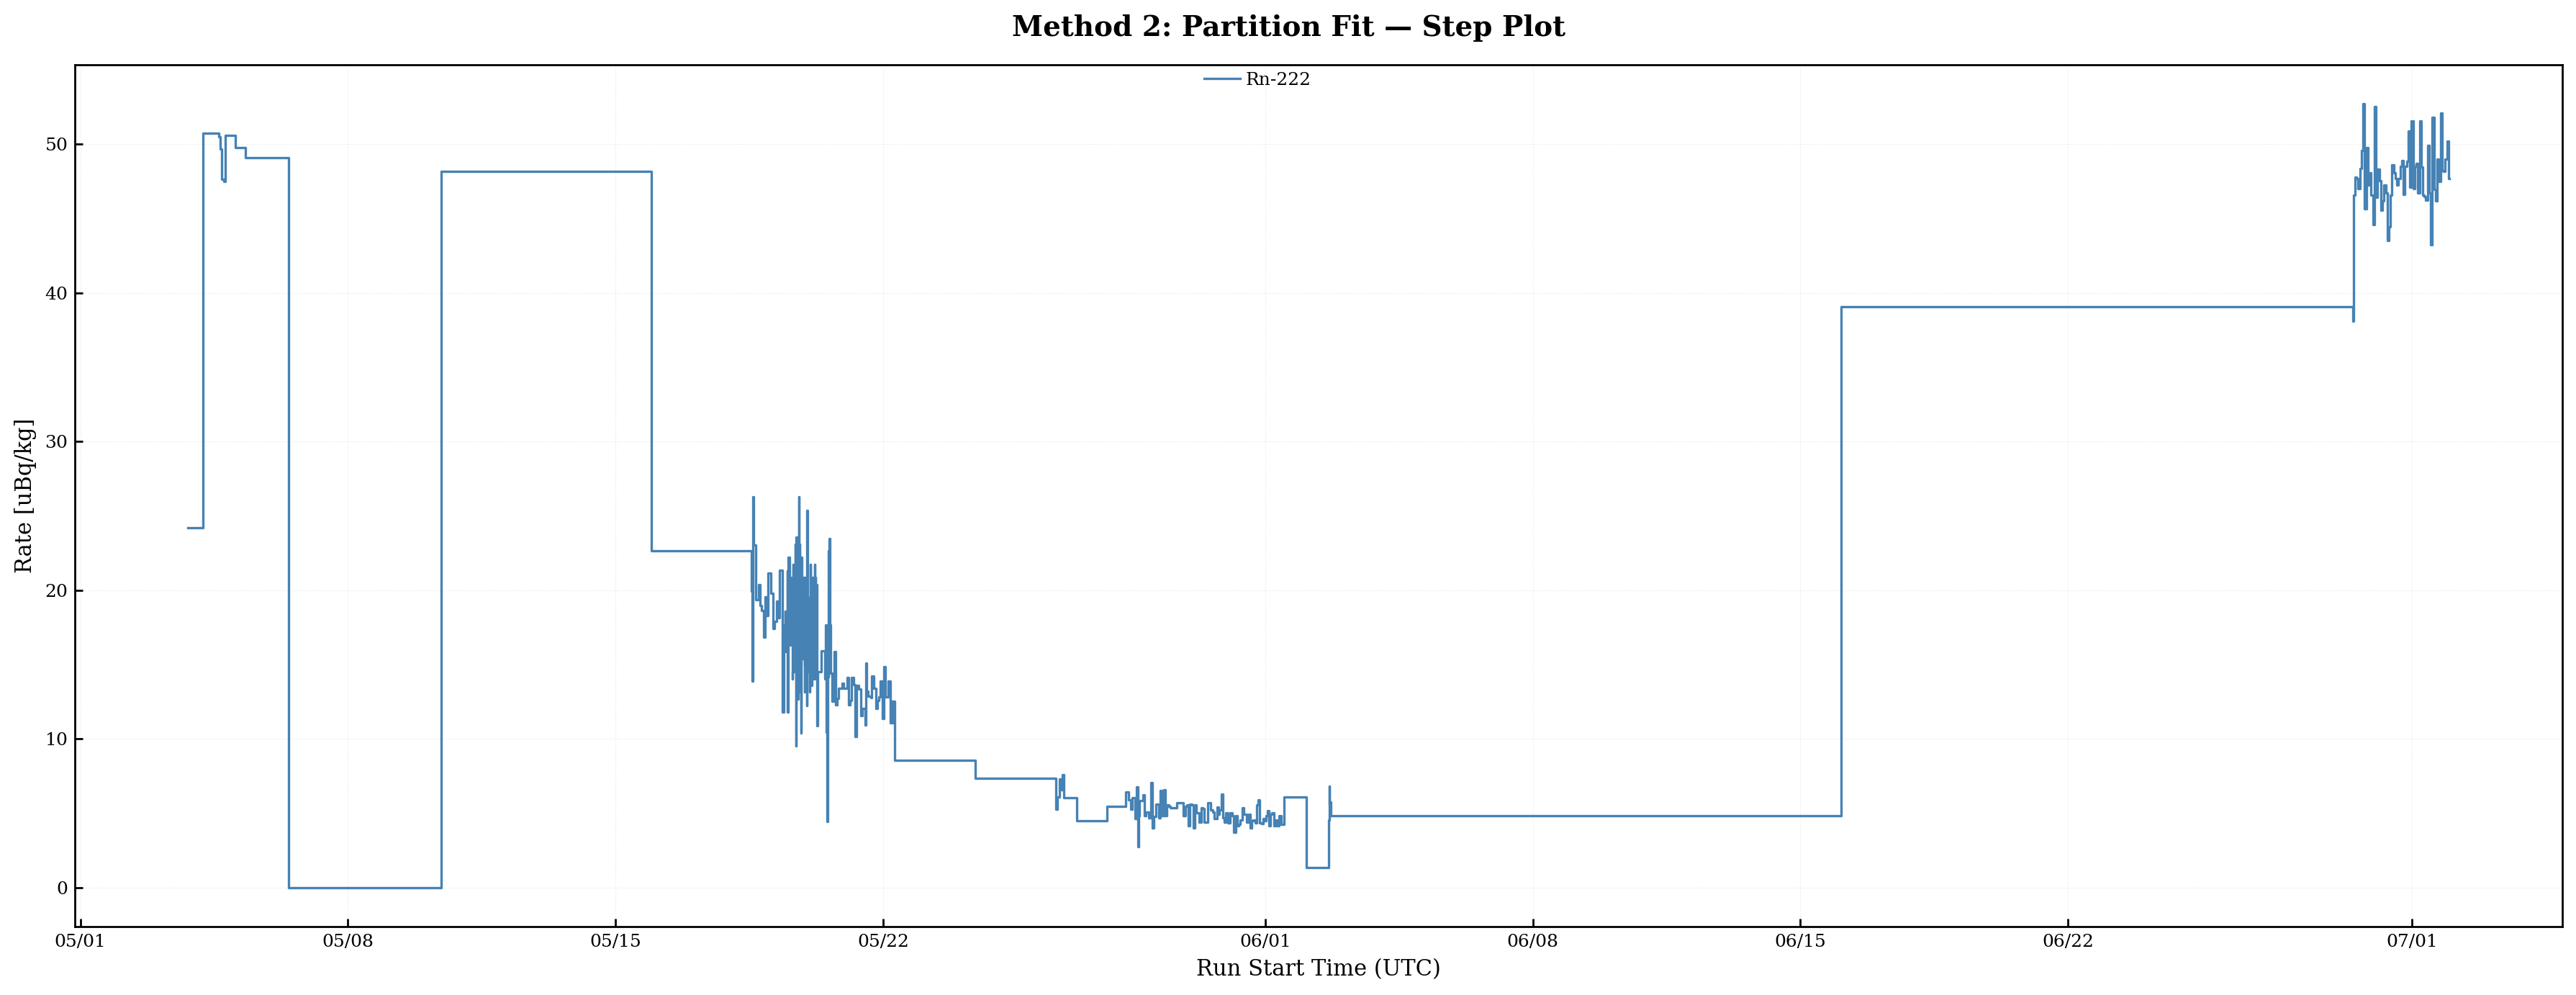

In [24]:
# M2 STEP — select isotopes + vlines

PLOT_ISOTOPES = ['Rn-222']

iso_list = [n for n in PLOT_ISOTOPES if n in df_m2['isotope'].unique()]
fig, ax = plt.subplots(figsize=(18, 7))
for name in iso_list:
    di = df_m2[df_m2['isotope'] == name].sort_values('start_s')
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.step(sd, di['rate_ukgb'].values, where='mid', color=STEP_COLORS[name], lw=1.2, label=name)

add_partition_vlines(ax); add_event_vlines(ax)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=12, loc='upper right', ncol=len(iso_list))
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('Run Start Time (UTC)', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Method 2: Partition Fit — Step Plot', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


# COMPARISON: M1 (left) vs M2 (right) — errorbar scatter

fig, axes = plt.subplots(N_PEAKS, 2, figsize=(20, 2.5*N_PEAKS), sharex='col')
if N_PEAKS == 1: axes = axes.reshape(1, 2)

for row, name in enumerate(PEAK_NAMES):
    # M1 (left)
    ax = axes[row, 0]
    di = df_m1[(df_m1['isotope'] == name) & (df_m1['rate_ukgb'] > 0)]
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=1.5, capsize=0, lw=0.2)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.set_title('M1: Run-by-Run Fit' if row == 0 else '', fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.2)
    add_partition_vlines(ax); add_event_vlines(ax)

    # M2 (right)
    ax = axes[row, 1]
    di = df_m2[(df_m2['isotope'] == name) & (df_m2['rate_ukgb'] > 0)]
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=1.5, capsize=0, lw=0.2)
    ax.set_title('M2: Partition Fit' if row == 0 else '', fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.2)
    add_partition_vlines(ax); add_event_vlines(ax)

axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1, 0].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1, 1].xaxis.set_major_locator(mdates.AutoDateLocator())
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Rn Alpha Rates — M1 (Left) vs M2 (Right)', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


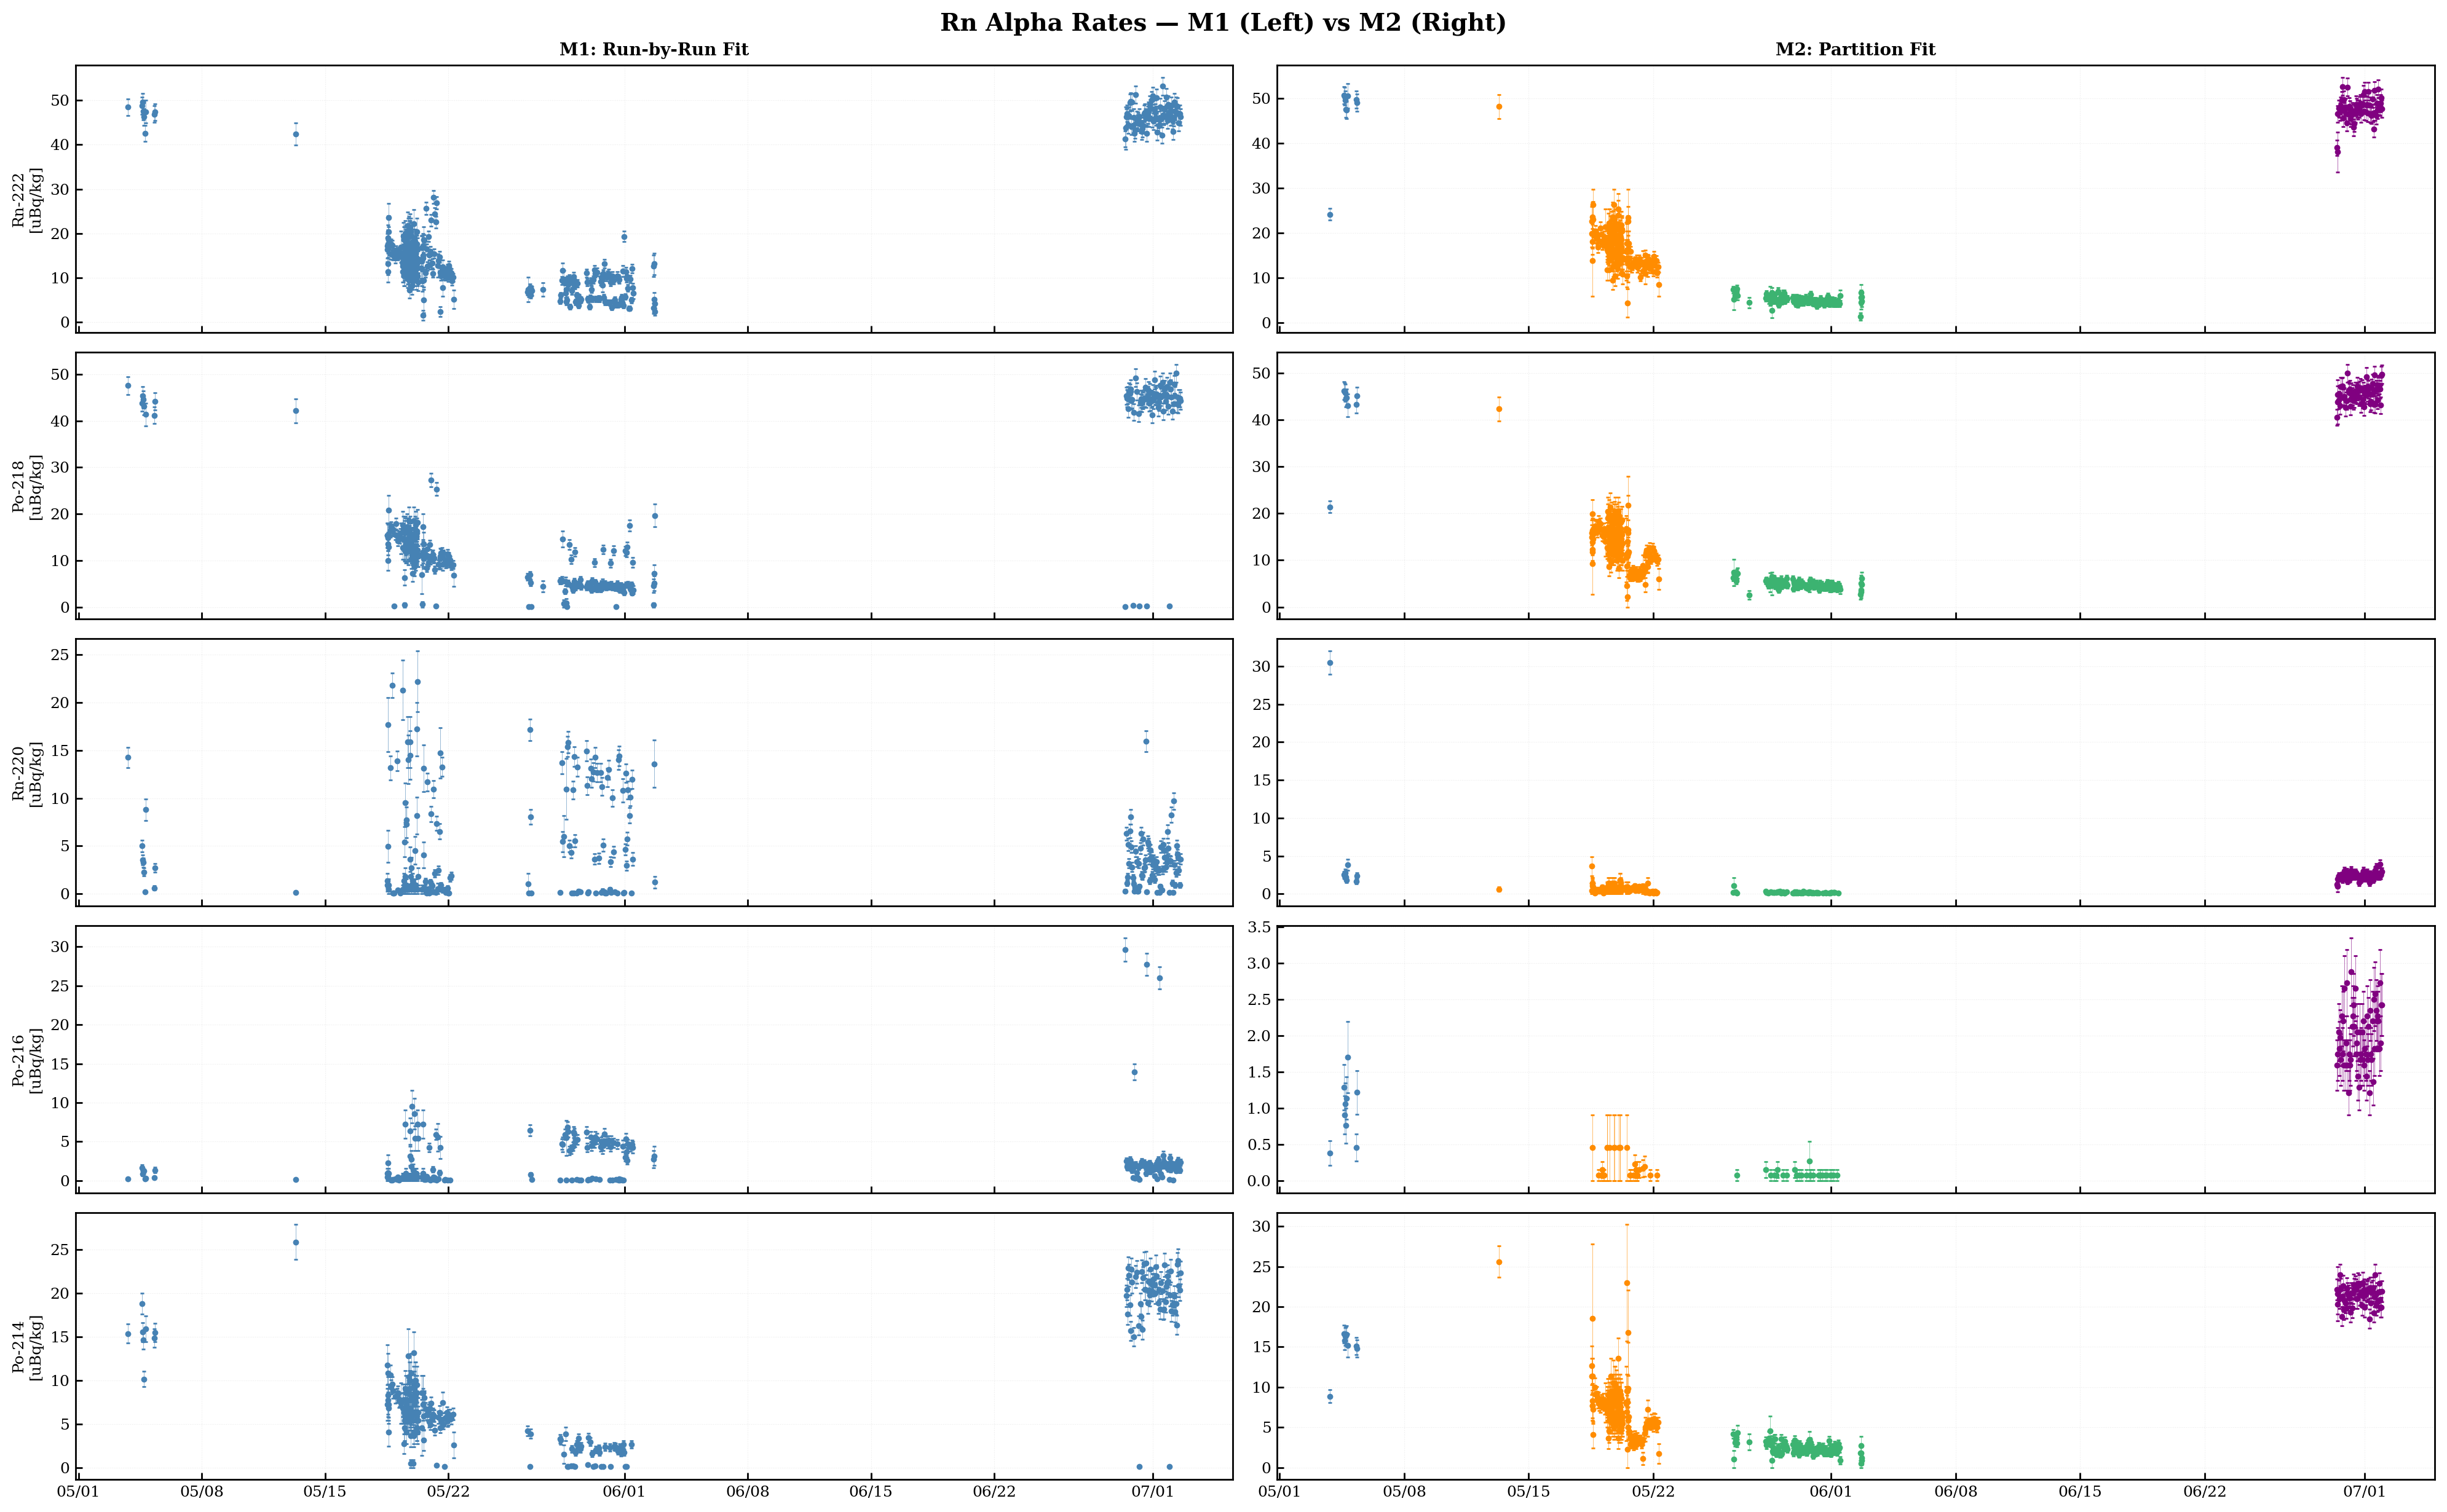

In [25]:
# ═══════════════════════════════════════════════════════════════
# COMPARISON: M1 (left) vs M2 (right) — errorbar scatter
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(N_PEAKS, 2, figsize=(20, 2.5*N_PEAKS), sharex='col')
if N_PEAKS == 1: axes = axes.reshape(1, 2)

for row, name in enumerate(PEAK_NAMES):
    # M1 (left)
    ax = axes[row, 0]
    di = df_m1[(df_m1['isotope'] == name) & (df_m1['rate_ukgb'] > 0)]
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['start_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=2.5, capsize=0, lw=0.2)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.set_title('M1: Run-by-Run Fit' if row == 0 else '', fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.2)

    # M2 (right)
    ax = axes[row, 1]
    di = df_m2[(df_m2['isotope'] == name) & (df_m2['rate_ukgb'] > 0)]
    for i, pname in enumerate([p[0] for p in partitions]):
        dp = di[di['partition'] == pname]
        if len(dp) == 0: continue
        sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['start_s']]
        ax.errorbar(np.array(sd), dp['rate_ukgb'].values, yerr=dp['rate_err_ukgb'].values,
                    fmt='o', color=pcolors[i], markersize=2.5, capsize=0, lw=0.2)
    ax.set_title('M2: Partition Fit' if row == 0 else '', fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.2)

axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1, 0].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1, 1].xaxis.set_major_locator(mdates.AutoDateLocator())
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Rn Alpha Rates — M1 (Left) vs M2 (Right)', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()

---
## 300 Uniform Time Bins

Divide the full time range into 300 equal-width bins for a model-independent view.

In [ ]:
# 300-BIN RATE EXTRACTION (using M2 partition-fit mu/sigma)

N_TIME_BINS = 300
t_min_s = rn_events['time'].min() / 1e9
t_max_s = rn_events['time'].max() / 1e9
t_edges_s = np.linspace(t_min_s, t_max_s, N_TIME_BINS + 1)
t_centers_s = 0.5 * (t_edges_s[:-1] + t_edges_s[1:])
t_edges_ns = (t_edges_s * 1e9).astype(np.int64)
bin_width_s = t_edges_s[1] - t_edges_s[0]

print(f'%d time bins, %.1f h each' % (N_TIME_BINS, bin_width_s/3600))
print('Range: ' + datetime.fromtimestamp(t_min_s, tz=timezone.utc).strftime('%m/%d') + ' - ' + datetime.fromtimestamp(t_max_s, tz=timezone.utc).strftime('%m/%d'))

N = N_PEAKS
tbin_rows = []
for pname, t0_s, t1_s in partitions:
    pfit = partition_fits.get(pname)
    if not pfit or not pfit['success']: continue
    for i, name in enumerate(PEAK_NAMES):
        mu, sig = pfit['fit_mu'][i], pfit['p_fit'][N + 1 + i]
        lo, hi = _get_window(i, mu, sig, pfit['fit_mu'])
        mask_iso = (rn_events['area_2_corrected'] >= lo) & (rn_events['area_2_corrected'] <= hi)
        t_sel = rn_events.loc[mask_iso, 'time'].values
        t0_ns, t1_ns = int(t0_s*1e9), int(t1_s*1e9)
        t_sel = t_sel[(t_sel >= t0_ns) & (t_sel < t1_ns)]
        counts, _ = np.histogram(t_sel, bins=t_edges_ns)
        rate = counts / bin_width_s * 1e6 / FMASS
        rerr = np.sqrt(np.maximum(counts, 1)) / bin_width_s * 1e6 / FMASS
        for j in range(N_TIME_BINS):
            tbin_rows.append({
                't_center_s': t_centers_s[j], 'isotope': name, 'partition': pname,
                'n_events': int(counts[j]), 'rate_ukgb': rate[j], 'rate_err_ukgb': rerr[j]})

df_tbin = pd.DataFrame(tbin_rows)
print('Time-binned rates: %d rows' % len(df_tbin))


In [ ]:
# 300-BIN SCATTER — source-colored + vlines

SOURCE_COLORS = {'S1-only': 'steelblue', 'S1+S2': 'darkorange'}

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]
for ax, name in zip(axes, PEAK_NAMES):
    di = df_tbin[(df_tbin['isotope'] == name) & (df_tbin['rate_ukgb'] > 0)]
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['t_center_s']]
    ax.errorbar(np.array(sd), di['rate_ukgb'].values, yerr=di['rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=2.5, capsize=0, lw=0.2)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.grid(True, alpha=0.25)
    add_partition_vlines(ax); add_event_vlines(ax)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('300 Uniform Time Bins — Errorbar Scatter', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


In [ ]:
# 300-BIN STEP — select isotopes + vlines

PLOT_ISOTOPES = ['Rn-222']

iso_list = [n for n in PLOT_ISOTOPES if n in df_tbin['isotope'].unique()]
fig, ax = plt.subplots(figsize=(18, 7))
for name in iso_list:
    di = df_tbin[df_tbin['isotope'] == name].sort_values('t_center_s')
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in di['t_center_s']]
    ax.step(sd, di['rate_ukgb'].values, where='mid', color=STEP_COLORS[name], lw=1.2, label=name)

add_partition_vlines(ax); add_event_vlines(ax)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=12, loc='upper right', ncol=len(iso_list))
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('300 Uniform Time Bins — Step Plot', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


---
## 7. Inspect Individual Fits

In [26]:
# ═══════════════════════════════════════════════════════════════
# PLOT SINGLE RUN
# ═══════════════════════════════════════════════════════════════

def plot_run_fit(run_name):
    n_bins = 100  # fixed, reliable
    fig, ax = plt.subplots(figsize=(14, 6))
    err = None

    # Get events
    rrow = runs_sr3[runs_sr3['name'] == run_name]
    if len(rrow) == 0:
        err = f'Run {run_name} not found'
    else:
        rrow = rrow.iloc[0]
        t0 = int(rrow['start_s'] * 1e9)
        t1 = int(float(rrow['end'].timestamp()) * 1e9)
        evts = rn_events[(rn_events['time'] >= t0) & (rn_events['time'] < t1)]
        n_ev = len(evts)

        if n_ev == 0:
            err = f'Run {run_name}: 0 events'
        else:
            hc, he, _ = ax.hist(evts['area_2_corrected'], bins=n_bins, range=[45e3, 80e3],
                                color='steelblue', alpha=0.5, label=f'Data ({n_ev} evts)')
            y_hi = hc.max() * 1.6

            fr = df_fits[df_fits['run'] == run_name]
            if len(fr) > 0:
                fr = fr.iloc[0]
                success = fr['success']
                method  = fr['method']
            else:
                success, method = False, None

            if success:
                bc = 0.5 * (he[:-1] + he[1:])
                cmap = plt.cm.tab10
                xf = np.linspace(45e3, 80e3, 2000)
                for i, name in enumerate(PEAK_NAMES):
                    mu = fr[f'fit_mu_{name}']
                    sig = fr[f'fit_sigma_{name}']
                    if np.isnan(mu) or np.isnan(sig):
                        continue
                    idx = np.argmin(np.abs(bc - mu))
                    amp_vis = min(hc[idx] if idx < len(hc) else y_hi*0.3, y_hi) * 1.05
                    g = amp_vis * np.exp(-0.5 * ((xf - mu) / sig)**2)
                    ax.plot(xf, g, '--', color=cmap(i), lw=1.5, alpha=0.8,
                            label=f'{name} μ={mu:.0f}')
                    ax.axvspan(mu - 2*sig, mu + 2*sig, color=cmap(i), alpha=0.06)

            status = fr.get('status', 'N/A') if 'fr' in dir() else 'N/A'
            ok_str = 'OK' if success else 'FAILED'
            ax.set_title(f'Run {run_name}  |  {ok_str} ({status})  |  method: {method}  |  {n_ev} events', fontsize=13)
            ax.set_ylim(0, y_hi)

    if err:
        print(err); return

    ax.set_xlabel('AFT + r² Corrected Area [PE]', fontsize=12)
    ax.set_ylabel('Counts/bin', fontsize=12)
    ax.legend(fontsize=7, ncol=2, loc='upper right')
    ax.grid(True, alpha=0.3)
    safe_tight(fig)
    plt.show()


print('plot_run_fit() defined.')
print('Usage: plot_run_fit("080510")')


plot_run_fit() defined.
Usage: plot_run_fit("080510")


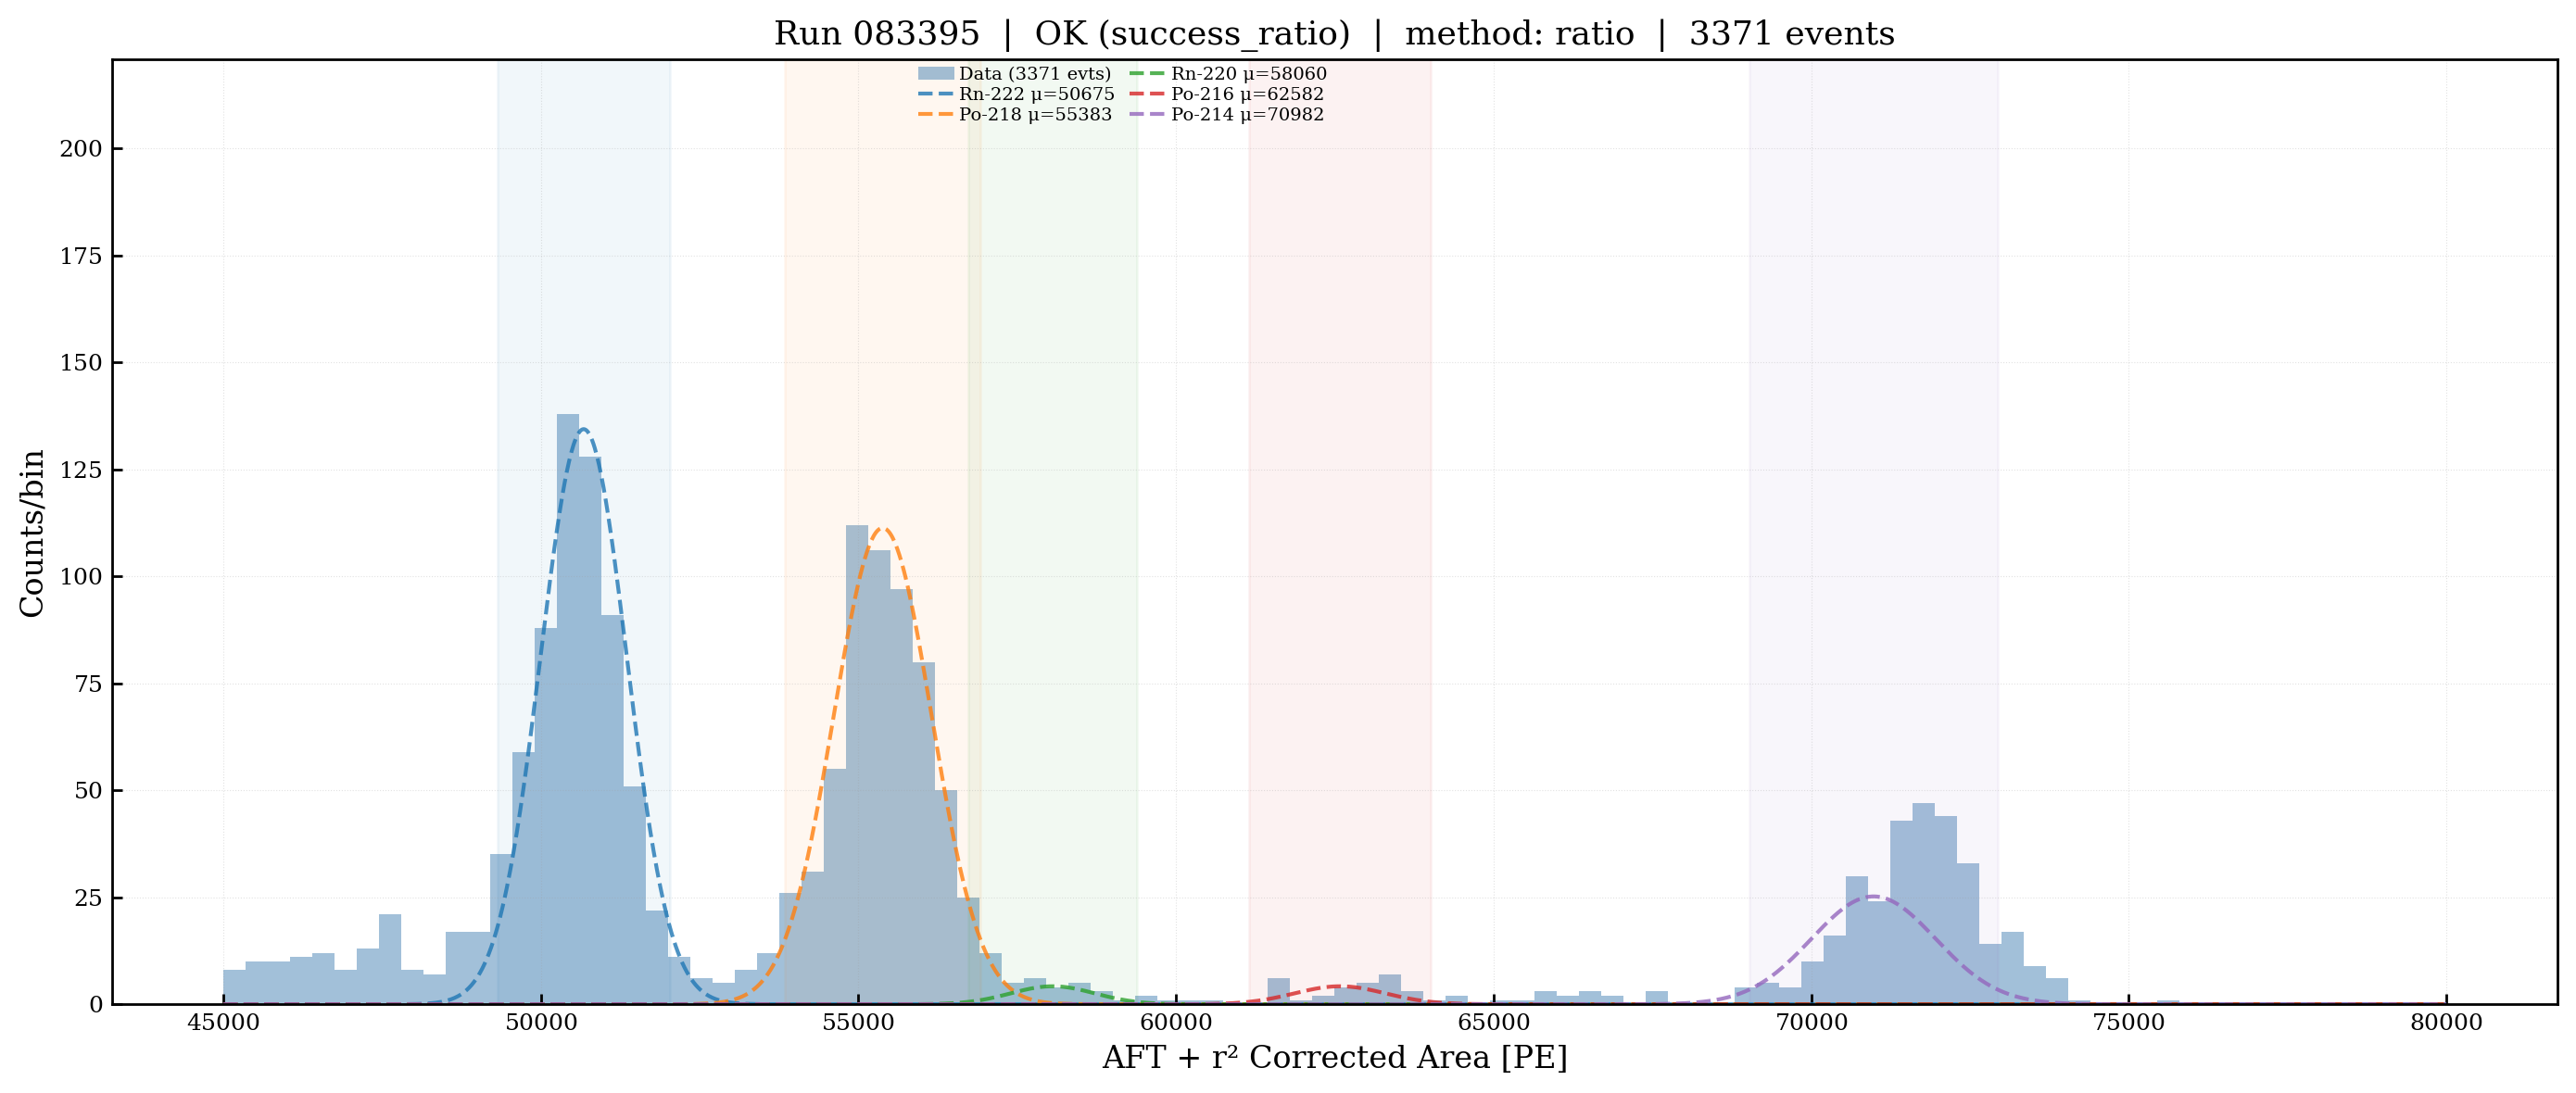

In [27]:
# ── Quick look at a random successful fit ──
ok_runs = df_fits[df_fits['success']]['run'].values
if len(ok_runs) > 0:
    plot_run_fit(np.random.choice(ok_runs))

---
## S1+S2 Data Analysis

Load the corrected s1+s2 data and apply the same per-run + partition fit pipeline.
Then merge with s1-only rates for the full combined trend.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# LOAD S1+S2 DATA + RUN LIST
# ═══════════════════════════════════════════════════════════════

rn_events_s1s2 = pd.read_pickle(
    '/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_corrected_for_fit_pp.pkl'
)
print(f'rn_events_s1s2: {len(rn_events_s1s2):,} events')
print(f'Columns: {list(rn_events_s1s2.columns)}')

# S1+S2 runs: NOT tagged s1_only
runs_s1s2 = st.select_runs(
    run_mode='tpc_bkg',
    exclude_tags=['abandon', 'messy', 'timing_issue', 's1_only'],
    available=('peak_basics'),
)
runs_s1s2['start_s'] = runs_s1s2['start'].apply(lambda x: x.timestamp())
runs_s1s2 = runs_s1s2[runs_s1s2['start_s'] >= pd.Timestamp('2026-05-01', tz='UTC').timestamp()]
print(f'S1+S2 runs: {len(runs_s1s2)}')
print(f'Run range: {runs_s1s2["name"].min()} - {runs_s1s2["name"].max()}')

In [ ]:
# ═══════════════════════════════════════════════════════════════
# S1+S2 PER-RUN FIT
# ═══════════════════════════════════════════════════════════════

df_fits_s1s2 = fit_all_runs_v2(runs_s1s2, rn_events_s1s2, rn222_ref=52000)

In [ ]:
# ═══════════════════════════════════════════════════════════════
# S1+S2 PARTITION FIT (same partitions as s1-only)
# ═══════════════════════════════════════════════════════════════

df_fits_s1s2['start_s'] = df_fits_s1s2['run'].map(runs_s1s2.set_index('name')['start_s'])
df_fits_s1s2['partition'] = df_fits_s1s2['start_s'].apply(assign_partition)

partition_fits_s1s2 = {}
for pname, t0, t1 in partitions:
    t0_ns, t1_ns = int(t0*1e9), int(t1*1e9)
    evts = rn_events_s1s2[(rn_events_s1s2['time'] >= t0_ns) & (rn_events_s1s2['time'] < t1_ns)]
    partition_fits_s1s2[pname] = fit_partition(evts, pname)

print('S1+S2 partition fits done.')

In [ ]:
# ═══════════════════════════════════════════════════════════════
# S1+S2 M2 RATES (partition-fit params per run)
# ═══════════════════════════════════════════════════════════════

results_m2_s1s2 = []
for _, row in df_fits_s1s2.iterrows():
    run_name = row['run']
    pname = row['partition']
    if pname is None: continue
    pfit = partition_fits_s1s2.get(pname)
    if not pfit or not pfit['success']: continue
    rrow = runs_s1s2[runs_s1s2['name'] == run_name]
    if len(rrow) == 0: continue
    rrow = rrow.iloc[0]
    t0 = int(rrow['start_s'] * 1e9)
    t1 = int(float(rrow['end'].timestamp()) * 1e9)
    lt = rrow.get('duration', t1/1e9 - t0/1e9)
    evts = rn_events_s1s2[(rn_events_s1s2['time'] >= t0) & (rn_events_s1s2['time'] < t1)]
    p, N = pfit['p_fit'], N_PEAKS
    for i, name in enumerate(PEAK_NAMES):
        mu, sig = pfit['fit_mu'][i], p[N + 1 + i]
        lo, hi = _get_window(i, mu, sig, pfit['fit_mu'])
        n = ((evts['area_2_corrected'] >= lo) & (evts['area_2_corrected'] <= hi)).sum()
        results_m2_s1s2.append({
            'run': run_name, 'start_s': rrow['start_s'],
            'end_s': float(rrow['end'].timestamp()), 'livetime_s': lt,
            'isotope': name, 'n_events': n, 'partition': pname,
            'rate_ukgb': n/lt*1e6/FMASS,
            'rate_err_ukgb': np.sqrt(max(n,1))/lt*1e6/FMASS})

df_m2_s1s2 = pd.DataFrame(results_m2_s1s2)
print(f'S1+S2 M2 rates: {len(df_m2_s1s2)} rows ({df_m2_s1s2["run"].nunique()} runs)')

---
## Combined S1-only + S1+S2 Trend

Merge both datasets and plot together, with different markers for each source.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# MERGE s1-only + s1+s2 rates
# ═══════════════════════════════════════════════════════════════

df_m2['source'] = 'S1-only'
df_m2_s1s2['source'] = 'S1+S2'
df_combined = pd.concat([df_m2, df_m2_s1s2], ignore_index=True)
df_combined = df_combined.sort_values('start_s').reset_index(drop=True)
print(f'Combined: {len(df_combined)} rows ({df_combined["run"].nunique()} runs)')
print(f'  S1-only runs: {df_combined[df_combined["source"]=="S1-only"]["run"].nunique()}')
print(f'  S1+S2  runs: {df_combined[df_combined["source"]=="S1+S2" ]["run"].nunique()}')

In [ ]:
# COMBINED SCATTER — 5 subplots, source-colored + vlines

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]

SOURCE_STYLE = {
    'S1-only': {'color': 'steelblue', 'marker': 'o'},
    'S1+S2':  {'color': 'darkorange', 'marker': 'o'},
}
seen = set()
for ax, name in zip(axes, PEAK_NAMES):
    di = df_combined[(df_combined['isotope'] == name) & (df_combined['rate_ukgb'] > 0)]
    for src, sty in SOURCE_STYLE.items():
        dp = di[di['source'] == src]
        if len(dp) == 0: continue
        sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['start_s']]
        lbl = src if src not in seen else None
        if lbl: seen.add(src)
        ax.errorbar(np.array(sd), dp['rate_ukgb'].values, yerr=dp['rate_err_ukgb'].values,
                    fmt='o', color=sty['color'], markersize=1.5, capsize=0, lw=0.2, label=lbl)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.legend(fontsize=12, loc='upper left')
    ax.grid(True, alpha=0.25)
    add_partition_vlines(ax); add_event_vlines(ax)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Combined S1-only + S1+S2 Rn Alpha Rates', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


In [ ]:
# COMBINED STEP — Rn-222, single continuous step (no source separation) + vlines

PLOT_ISOTOPES = ['Rn-222']

iso_list = [n for n in PLOT_ISOTOPES if n in df_combined['isotope'].unique()]
fig, ax = plt.subplots(figsize=(18, 7))
for name in iso_list:
    iso_data = df_combined[df_combined['isotope'] == name]
    # Combine all sources into one continuous step
    combined = iso_data.sort_values('start_s')
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in combined['start_s']]
    ax.step(sd, combined['rate_ukgb'].values, where='mid',
            color='steelblue', lw=1.5, label=name)

add_partition_vlines(ax)
add_event_vlines(ax)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Combined Step Plot — S1-only + S1+S2', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


---
## Combined Fitted Mu — All Runs Time Trend

Merge fitted mu values from S1-only + S1+S2 per-run fits to check gain stability.

In [ ]:
# Merge df_fits (S1-only) and df_fits_s1s2
def add_start_s(fits_df, runs_df):
    indexed = runs_df.set_index('name')
    return fits_df['run'].map(indexed['start_s'])

df_fits['source'] = 'S1-only'
df_fits_s1s2['source'] = 'S1+S2'
df_fits_s1s2['start_s'] = add_start_s(df_fits_s1s2, runs_s1s2)
df_fits['start_s'] = df_fits['run'].map(runs_sr3_indexed['start_s'])

df_fits_all = pd.concat([
    df_fits[df_fits['success']],
    df_fits_s1s2[df_fits_s1s2['success']]
], ignore_index=True).sort_values('start_s')

print(f'Combined fits: {len(df_fits_all)} successful ({len(df_fits_all["run"].unique())} runs)')
print(f'  S1-only: {(df_fits_all["source"]=="S1-only").sum()}')
print(f'  S1+S2:   {(df_fits_all["source"]=="S1+S2").sum()}')


In [ ]:
# FITTED Mu TREND — 5 subplots, source-colored + vlines

SOURCE_COLORS = {'S1-only': 'steelblue', 'S1+S2': 'darkorange'}

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]
seen = set()
for ax, name in zip(axes, PEAK_NAMES):
    col = f'fit_mu_{name}'
    for src, color in SOURCE_COLORS.items():
        dp = df_fits_all[df_fits_all['source'] == src]
        sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['start_s']]
        lbl = src if src not in seen else None
        if lbl: seen.add(src)
        ax.plot(np.array(sd), dp[col].values/1e3, 'o', color=color,
                markersize=1.5, alpha=0.5, label=lbl)
    ax.set_ylabel(f'{name}\n[10^3 PE]', fontsize=9)
    ax.legend(fontsize=10, loc='upper right')
    ax.grid(True, alpha=0.2)
    add_partition_vlines(ax)
    add_event_vlines(ax)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Fitted Mu — All Runs (S1-only + S1+S2)', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


---
## 500 Uniform Time Bins — Combined S1-only + S1+S2


In [ ]:
# 500-BIN combined rate extraction

N_TIME_BINS = 500
t_min_s = min(rn_events['time'].min(), rn_events_s1s2['time'].min()) / 1e9
t_max_s = max(rn_events['time'].max(), rn_events_s1s2['time'].max()) / 1e9
t_edges_s = np.linspace(t_min_s, t_max_s, N_TIME_BINS + 1)
t_centers_s = 0.5 * (t_edges_s[:-1] + t_edges_s[1:])
t_edges_ns = (t_edges_s * 1e9).astype(np.int64)
bin_width_s = t_edges_s[1] - t_edges_s[0]

print('%d time bins, %.1f h each' % (N_TIME_BINS, bin_width_s/3600))
print('Range: ' + datetime.fromtimestamp(t_min_s, tz=timezone.utc).strftime('%m/%d') + ' - ' + datetime.fromtimestamp(t_max_s, tz=timezone.utc).strftime('%m/%d'))

def extract_tbin(data_evts, data_fits, source_label):
    rows = []
    N = N_PEAKS
    for pname, t0_s, t1_s in partitions:
        pfit = data_fits.get(pname)
        if not pfit or not pfit['success']: continue
        for i, name in enumerate(PEAK_NAMES):
            mu, sig = pfit['fit_mu'][i], pfit['p_fit'][N + 1 + i]
            lo, hi = _get_window(i, mu, sig, pfit['fit_mu'])
            mask = (data_evts['area_2_corrected'] >= lo) & (data_evts['area_2_corrected'] <= hi)
            t_sel = data_evts.loc[mask, 'time'].values
            t0_ns, t1_ns = int(t0_s*1e9), int(t1_s*1e9)
            t_sel = t_sel[(t_sel >= t0_ns) & (t_sel < t1_ns)]
            counts, _ = np.histogram(t_sel, bins=t_edges_ns)
            rate = counts / bin_width_s * 1e6 / FMASS
            rerr = np.sqrt(np.maximum(counts, 1)) / bin_width_s * 1e6 / FMASS
            for j in range(N_TIME_BINS):
                rows.append({
                    't_center_s': t_centers_s[j], 'isotope': name,
                    'n_events': int(counts[j]), 'source': source_label,
                    'rate_ukgb': rate[j], 'rate_err_ukgb': rerr[j]})
    return rows

t500_rows = extract_tbin(rn_events, partition_fits, 'S1-only')
t500_rows += extract_tbin(rn_events_s1s2, partition_fits_s1s2, 'S1+S2')
df_t500 = pd.DataFrame(t500_rows)
print('Combined 500-bin rates: %d rows' % len(df_t500))


In [ ]:
# 500-BIN SCATTER — source-colored + vlines

SOURCE_COLORS = {'S1-only': 'steelblue', 'S1+S2': 'darkorange'}

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5*N_PEAKS), sharex=True)
if N_PEAKS == 1: axes = [axes]
seen = set()
for ax, name in zip(axes, PEAK_NAMES):
    di = df_t500[(df_t500['isotope'] == name) & (df_t500['rate_ukgb'] > 0)]
    for src, color in SOURCE_COLORS.items():
        dp = di[di['source'] == src]
        if len(dp) == 0: continue
        sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in dp['t_center_s']]
        lbl = src if src not in seen else None
        if lbl: seen.add(src)
        ax.errorbar(np.array(sd), dp['rate_ukgb'].values, yerr=dp['rate_err_ukgb'].values,
                    fmt='o', color=color, markersize=2, capsize=0, lw=0.15, label=lbl)
    ax.set_ylabel(f'{name}\n[uBq/kg]', fontsize=9)
    ax.legend(fontsize=12, loc='upper left')
    ax.grid(True, alpha=0.25)
    add_partition_vlines(ax); add_event_vlines(ax)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('500 Uniform Time Bins — Combined S1-only + S1+S2', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()


In [ ]:
# 500-BIN STEP — Rn-222, single continuous + vlines

PLOT_ISOTOPES = ['Rn-222']
iso_list = [n for n in PLOT_ISOTOPES if n in df_t500['isotope'].unique()]
fig, ax = plt.subplots(figsize=(18, 7))
for name in iso_list:
    combined = df_t500[(df_t500['isotope'] == name) & (df_t500['rate_ukgb'] > 0)].sort_values('t_center_s')
    sd = [datetime.fromtimestamp(s, tz=timezone.utc) for s in combined['t_center_s']]
    ax.step(sd, combined['rate_ukgb'].values, where='mid',
            color='steelblue', lw=1.2, label=name)

add_partition_vlines(ax)
add_event_vlines(ax)
ax.set_ylabel('Rate [uBq/kg]', fontsize=11)
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.set_xlabel('UTC Time', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('500 Uniform Time Bins — Step Plot', fontsize=14, fontweight='bold')
safe_tight(fig); plt.show()
